# Questset Exploratory Data Analysis

This notebook performs a structured exploratory analysis of the Questset dataset before final feature engineering and model development.

## Objectives

- Understand the dataset structure and balance.
- Explore pre-session, post-session, and change in SSQ scores.
- Investigate game, speed, session, and participant effects.
- Examine demographic and experience-related factors.
- Assess movement-data quality and distributions.
- Study relationships between early movement behavior and cybersickness.
- Compare 1-, 3-, and 5-minute observation windows.
- Identify outliers and unusual sessions.
- Use EDA findings to guide feature engineering and later modeling.

## 1. Dataset Structure and Basic Checks

We first verify the number of participants, sessions, games, speed conditions, and session ordering. This confirms that the processed dataset matches the expected Questset structure before deeper analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sessions = pd.read_csv("../data/processed/questset_sessions_with_ssq.csv")
movement = pd.read_csv("../data/processed/questset_movement_features.csv")

print("Sessions shape:", sessions.shape)
print("Movement features shape:", movement.shape)

print("\nParticipants:", sessions["participant_id"].nunique())
print("Sessions:", len(sessions))

print("\nGame counts:")
print(sessions["game_name"].value_counts())

print("\nSpeed counts:")
print(sessions["game_speed"].value_counts())

print("\nSession number counts:")
print(sessions["session_number"].value_counts())

Sessions shape: (120, 28)
Movement features shape: (360, 61)

Participants: 60
Sessions: 120

Game counts:
game_name
Cooking Simulator     30
Beat Saber            30
Forklift Simulator    30
Medal of Honor        30
Name: count, dtype: int64

Speed counts:
game_speed
slow    60
fast    60
Name: count, dtype: int64

Session number counts:
session_number
1    60
2    60
Name: count, dtype: int64


## 2. SSQ Distribution Analysis

We next examine the distribution of cybersickness scores before and after each VR session, as well as the change in SSQ score (`delta_ssq_total`).

This helps us understand:
- how severe cybersickness is in the dataset,
- whether the target is skewed,
- how many participants report no symptoms,
- whether some sessions contain extreme sickness scores,
- and whether `post_ssq_total` or `delta_ssq_total` may be more suitable for later modeling.

In [2]:
ssq_cols = [
    "pre_ssq_total",
    "post_ssq_total",
    "delta_ssq_total"
]

print("SSQ summary statistics:")
display(sessions[ssq_cols].describe().round(2))

print("\nZero-value counts:")
for col in ssq_cols:
    count = (sessions[col] == 0).sum()
    pct = count / len(sessions) * 100
    print(f"{col}: {count} ({pct:.1f}%)")

print("\nNegative delta SSQ:")
negative = (sessions["delta_ssq_total"] < 0).sum()
print(f"{negative} sessions ({negative / len(sessions) * 100:.1f}%)")

print("\nHighest post-session SSQ sessions:")
display(
    sessions[
        [
            "participant_id",
            "session_number",
            "game_name",
            "game_speed",
            "pre_ssq_total",
            "post_ssq_total",
            "delta_ssq_total"
        ]
    ]
    .sort_values("post_ssq_total", ascending=False)
    .head(10)
)

SSQ summary statistics:


,pre_ssq_total,post_ssq_total,delta_ssq_total
count,120.00,120.00,120.00
mean,6.02,18.36,12.34
std,8.55,20.76,21.72
min,0.00,0.00,-41.14
25%,0.00,3.74,0.00
50%,3.74,11.22,7.48
75%,8.42,26.18,18.70
max,41.14,108.46,108.46



Zero-value counts:
pre_ssq_total: 54 (45.0%)
post_ssq_total: 27 (22.5%)
delta_ssq_total: 24 (20.0%)

Negative delta SSQ:
18 sessions (15.0%)

Highest post-session SSQ sessions:


,participant_id,session_number,game_name,game_speed,pre_ssq_total,post_ssq_total,delta_ssq_total
45,group1_order2_user2,2,Cooking Simulator,slow,0.00,108.46,108.46
51,group1_order2_user5,2,Cooking Simulator,slow,3.74,108.46,104.72
70,group2_order1_user13,1,Forklift Simulator,slow,3.74,89.76,86.02
28,group1_order1_user9,1,Cooking Simulator,slow,0.00,67.32,67.32
100,group2_order2_user13,1,Medal of Honor,fast,7.48,63.58,56.10
111,group2_order2_user5,2,Forklift Simulator,slow,26.18,59.84,33.66
110,group2_order2_user5,1,Medal of Honor,fast,7.48,56.10,48.62
22,group1_order1_user6,1,Cooking Simulator,slow,0.00,56.10,56.10
39,group1_order2_user12,2,Cooking Simulator,slow,0.00,48.62,48.62
119,group2_order2_user9,2,Forklift Simulator,slow,33.66,48.62,14.96


### SSQ Distribution Plots

The following plots visualize the shape of the pre-session, post-session, and change-in-SSQ distributions. Particular attention is given to skewness, concentration near zero, and unusually high values.

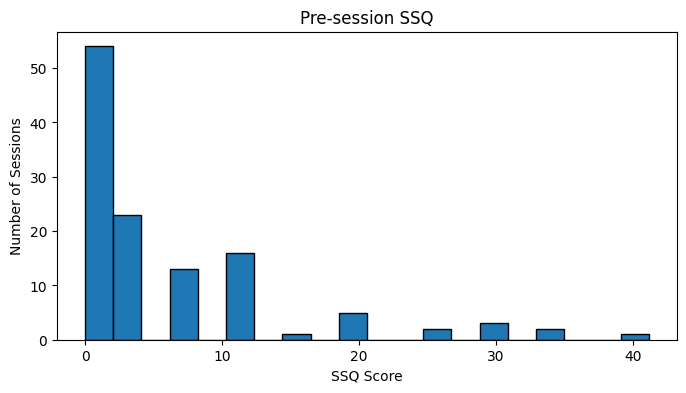

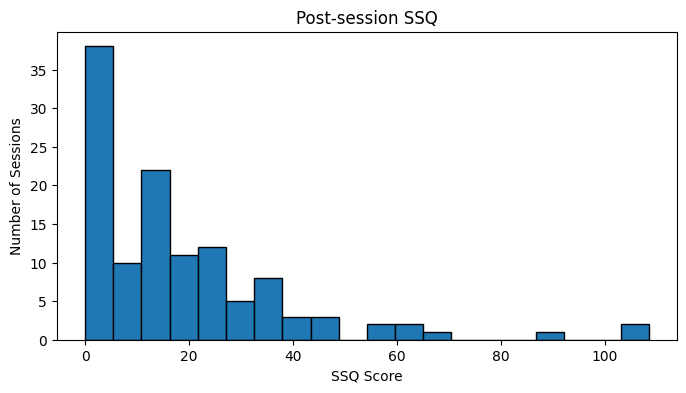

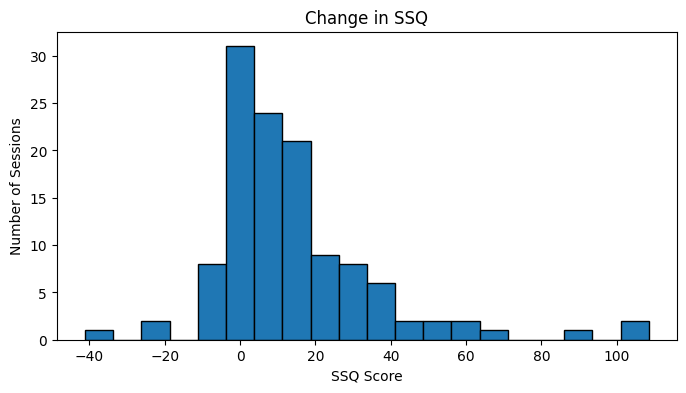

In [3]:
for col, title in [
    ("pre_ssq_total", "Pre-session SSQ"),
    ("post_ssq_total", "Post-session SSQ"),
    ("delta_ssq_total", "Change in SSQ")
]:
    plt.figure(figsize=(8, 4))
    plt.hist(sessions[col], bins=20, edgecolor="black")
    plt.xlabel("SSQ Score")
    plt.ylabel("Number of Sessions")
    plt.title(title)
    plt.show()

### Initial SSQ Findings

The SSQ targets are not normally distributed.

- Pre-session sickness is generally low, with 45% of sessions having a pre-SSQ score of zero.
- Post-session SSQ is strongly right-skewed, with most sessions concentrated at relatively low values and a small number of very high-sickness sessions.
- Delta SSQ is also right-skewed and contains both positive and negative values.
- 20% of sessions show no change in SSQ, while 15% show a reduction in reported symptoms.
- Several extreme post-session SSQ values are associated with slow games, particularly Cooking Simulator and Forklift Simulator.

These findings suggest that later modeling should account for target skewness and extreme observations rather than assuming a simple approximately normal regression target.

## 3. Game, Speed, and Session Effects

We now investigate whether cybersickness differs systematically across games, game-speed categories, and whether the VR exposure occurred in the first or second session.

This is important because strong contextual effects may explain part of the variation in SSQ independently of head movement.

In [4]:
game_summary = (
    sessions.groupby("game_name")
    .agg(
        n=("post_ssq_total", "size"),
        pre_mean=("pre_ssq_total", "mean"),
        post_mean=("post_ssq_total", "mean"),
        post_median=("post_ssq_total", "median"),
        delta_mean=("delta_ssq_total", "mean"),
        delta_median=("delta_ssq_total", "median"),
        post_std=("post_ssq_total", "std")
    )
    .round(2)
)

print("SSQ by game:")
display(game_summary)

speed_summary = (
    sessions.groupby("game_speed")
    .agg(
        n=("post_ssq_total", "size"),
        post_mean=("post_ssq_total", "mean"),
        post_median=("post_ssq_total", "median"),
        delta_mean=("delta_ssq_total", "mean"),
        delta_median=("delta_ssq_total", "median")
    )
    .round(2)
)

print("\nSSQ by game speed:")
display(speed_summary)

session_summary = (
    sessions.groupby("session_number")
    .agg(
        n=("post_ssq_total", "size"),
        pre_mean=("pre_ssq_total", "mean"),
        post_mean=("post_ssq_total", "mean"),
        delta_mean=("delta_ssq_total", "mean")
    )
    .round(2)
)

print("\nSSQ by session number:")
display(session_summary)

SSQ by game:


,n,pre_mean,post_mean,post_median,delta_mean,delta_median,post_std
game_name,,,,,,,
Beat Saber,30,7.85,7.73,5.61,-0.12,0.00,7.98
Cooking Simulator,30,2.12,26.18,16.83,24.06,13.09,28.58
Forklift Simulator,30,7.48,21.32,14.96,13.84,9.35,21.05
Medal of Honor,30,6.61,18.20,18.70,11.59,11.22,15.98



SSQ by game speed:


,n,post_mean,post_median,delta_mean,delta_median
game_speed,,,,,
fast,60,12.97,11.22,5.73,3.74
slow,60,23.75,14.96,18.95,11.22



SSQ by session number:


,n,pre_mean,post_mean,delta_mean
session_number,,,,
1,60,3.43,19.26,15.83
2,60,8.60,17.45,8.85


<Figure size 900x500 with 0 Axes>

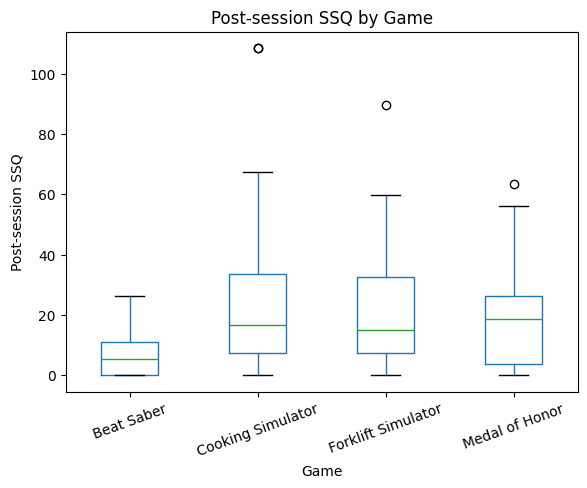

In [5]:
plt.figure(figsize=(9, 5))
sessions.boxplot(
    column="post_ssq_total",
    by="game_name",
    grid=False,
    rot=20
)
plt.title("Post-session SSQ by Game")
plt.suptitle("")
plt.xlabel("Game")
plt.ylabel("Post-session SSQ")
plt.show()

<Figure size 600x500 with 0 Axes>

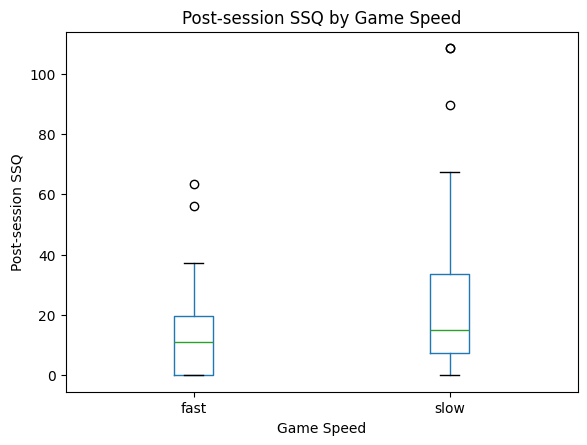

In [6]:
plt.figure(figsize=(6, 5))
sessions.boxplot(
    column="post_ssq_total",
    by="game_speed",
    grid=False
)
plt.title("Post-session SSQ by Game Speed")
plt.suptitle("")
plt.xlabel("Game Speed")
plt.ylabel("Post-session SSQ")
plt.show()

<Figure size 600x500 with 0 Axes>

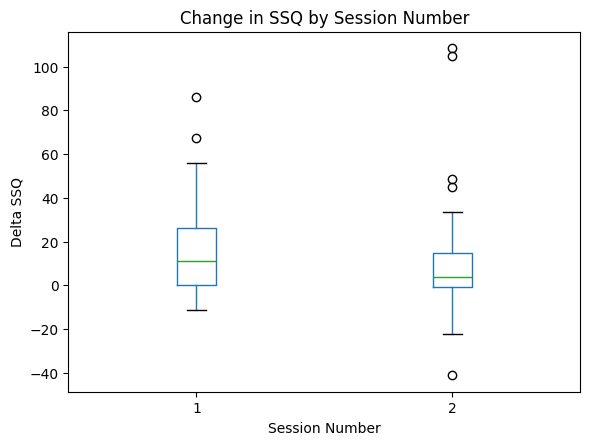

In [7]:
plt.figure(figsize=(6, 5))
sessions.boxplot(
    column="delta_ssq_total",
    by="session_number",
    grid=False
)
plt.title("Change in SSQ by Session Number")
plt.suptitle("")
plt.xlabel("Session Number")
plt.ylabel("Delta SSQ")
plt.show()

### Findings: Game and Session Effects

- Cybersickness differs substantially across games.
- Beat Saber shows the lowest post-session SSQ and almost no average increase in sickness.
- Cooking Simulator shows the largest average increase in SSQ and the greatest variability.
- Forklift Simulator and Medal of Honor show intermediate sickness levels.
- Sessions labeled as slow have higher average SSQ than fast sessions; however, game speed is directly tied to game identity in Questset, so speed cannot yet be interpreted as an independent causal effect.
- Session 1 produces a larger average increase in SSQ than session 2.
- Pre-session SSQ is considerably higher before session 2, suggesting possible symptom carryover from the first exposure.
- The distributions contain several extreme observations, so later analyses should consider medians, paired comparisons, and robust statistics in addition to means.

## 4. Within-Participant and Order Effects

Each participant completed two VR sessions. Therefore, observations from the same participant are not independent.

This section investigates:

- whether participants who experience high sickness in one session also tend to experience high sickness in the other,
- whether sickness differs systematically between the first and second exposure,
- whether the experimental order affects the results,
- and whether symptoms from the first session may carry over into the second session.

Understanding these effects is important for both feature engineering and participant-independent model evaluation.

In [8]:
# Pivot sessions so each participant has session 1 and session 2 side by side
paired = sessions.pivot(
    index="participant_id",
    columns="session_number",
    values=[
        "pre_ssq_total",
        "post_ssq_total",
        "delta_ssq_total"
    ]
)

paired.columns = [
    f"{metric}_session{session}"
    for metric, session in paired.columns
]

paired = paired.reset_index()

print("Paired participants:", len(paired))

print("\nCorrelation between session 1 and session 2:")
print(
    paired[
        [
            "post_ssq_total_session1",
            "post_ssq_total_session2",
            "delta_ssq_total_session1",
            "delta_ssq_total_session2"
        ]
    ].corr().round(3)
)

print("\nMean paired differences:")
print(
    "Post SSQ session2 - session1:",
    (
        paired["post_ssq_total_session2"]
        - paired["post_ssq_total_session1"]
    ).mean()
)

print(
    "Delta SSQ session2 - session1:",
    (
        paired["delta_ssq_total_session2"]
        - paired["delta_ssq_total_session1"]
    ).mean()
)

Paired participants: 60

Correlation between session 1 and session 2:
                          post_ssq_total_session1  post_ssq_total_session2  \
post_ssq_total_session1                     1.000                    0.174   
post_ssq_total_session2                     0.174                    1.000   
delta_ssq_total_session1                    0.964                    0.077   
delta_ssq_total_session2                   -0.176                    0.900   

                          delta_ssq_total_session1  delta_ssq_total_session2  
post_ssq_total_session1                      0.964                    -0.176  
post_ssq_total_session2                      0.077                     0.900  
delta_ssq_total_session1                     1.000                    -0.230  
delta_ssq_total_session2                    -0.230                     1.000  

Mean paired differences:
Post SSQ session2 - session1: -1.8076666666666672
Delta SSQ session2 - session1: -6.9813333333333345


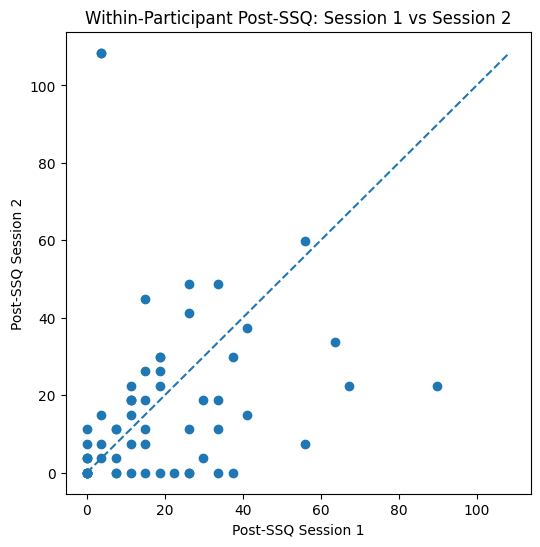

In [9]:
plt.figure(figsize=(6, 6))

plt.scatter(
    paired["post_ssq_total_session1"],
    paired["post_ssq_total_session2"]
)

max_val = max(
    paired["post_ssq_total_session1"].max(),
    paired["post_ssq_total_session2"].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--"
)

plt.xlabel("Post-SSQ Session 1")
plt.ylabel("Post-SSQ Session 2")
plt.title("Within-Participant Post-SSQ: Session 1 vs Session 2")
plt.show()

In [10]:
order_summary = (
    sessions.groupby(["group", "order", "session_number"])
    .agg(
        n=("post_ssq_total", "size"),
        pre_mean=("pre_ssq_total", "mean"),
        post_mean=("post_ssq_total", "mean"),
        delta_mean=("delta_ssq_total", "mean"),
        delta_median=("delta_ssq_total", "median")
    )
    .round(2)
)

display(order_summary)

n  pre_mean  post_mean  delta_mean  delta_median
group order session_number                                                   
1     1     1               15      2.74      26.93       24.19         22.44
            2               15     13.96       8.98       -4.99          0.00
      2     1               15      1.75       6.48        4.74          3.74
            2               15      1.50      25.43       23.94          7.48
2     1     1               15      4.74      23.19       18.45         11.22
            2               15      8.73      15.96        7.23         11.22
      2     1               15      4.49      20.45       15.96         11.22
            2               15     10.22      19.45        9.23          3.74

### Findings: Within-Participant and Order Effects

- Post-session SSQ shows only weak consistency across the two sessions of the same participant.
- The correlation between session-1 and session-2 post-SSQ is low, indicating that cybersickness is not explained only by stable participant susceptibility.
- Delta SSQ is also weakly related across sessions.
- On average, session 2 produces a smaller increase in SSQ than session 1.
- Experimental order appears to interact strongly with session number and game identity.
- Some order groups show large sickness increases in the first session but little or negative change in the second, while other groups show the reverse pattern.
- This indicates that game identity, exposure order, adaptation, and carryover effects should be considered explicitly during feature engineering and modeling.

## 5. Demographic and Experience Effects

This section examines whether participant characteristics are associated with cybersickness.

We investigate:

- age,
- gender,
- previous VR experience,
- previous gaming experience.

These variables may represent differences in prior adaptation, familiarity with virtual environments, or individual susceptibility.

In [11]:
demo_cols = [
    "age",
    "vr_experience",
    "gaming_experience",
    "pre_ssq_total",
    "post_ssq_total",
    "delta_ssq_total"
]

print("Correlations:")
display(
    sessions[demo_cols]
    .corr()
    .round(3)
)

print("\nGender summary:")
display(
    sessions.groupby("gender")
    .agg(
        n=("post_ssq_total", "size"),
        age_mean=("age", "mean"),
        post_mean=("post_ssq_total", "mean"),
        post_median=("post_ssq_total", "median"),
        delta_mean=("delta_ssq_total", "mean"),
        delta_median=("delta_ssq_total", "median")
    )
    .round(2)
)

print("\nVR experience summary:")
display(
    sessions.groupby("vr_experience")
    .agg(
        n=("post_ssq_total", "size"),
        post_mean=("post_ssq_total", "mean"),
        delta_mean=("delta_ssq_total", "mean")
    )
    .round(2)
)

print("\nGaming experience summary:")
display(
    sessions.groupby("gaming_experience")
    .agg(
        n=("post_ssq_total", "size"),
        post_mean=("post_ssq_total", "mean"),
        delta_mean=("delta_ssq_total", "mean")
    )
    .round(2)
)

Correlations:


,age,vr_experience,gaming_experience,pre_ssq_total,post_ssq_total,delta_ssq_total
age,1.000,-0.032,-0.137,0.084,-0.044,-0.075
vr_experience,-0.032,1.000,0.184,-0.092,-0.083,-0.043
gaming_experience,-0.137,0.184,1.000,0.122,0.030,-0.020
pre_ssq_total,0.084,-0.092,0.122,1.000,0.091,-0.307
post_ssq_total,-0.044,-0.083,0.030,0.091,1.000,0.920
delta_ssq_total,-0.075,-0.043,-0.020,-0.307,0.920,1.000



Gender summary:


,n,age_mean,post_mean,post_median,delta_mean,delta_median
gender,,,,,,
Female,44,26.95,15.64,11.22,10.54,3.74
Male,76,26.05,19.93,14.96,13.39,7.48



VR experience summary:


,n,post_mean,delta_mean
vr_experience,,,
1,68,18.92,13.14
2,32,19.05,10.17
3,16,17.76,15.66
4,2,9.35,3.74
5,2,1.87,1.87



Gaming experience summary:


,n,post_mean,delta_mean
gaming_experience,,,
1,16,15.43,11.92
2,26,18.27,11.22
3,24,21.97,16.36
4,24,14.96,12.00
5,30,19.82,10.60


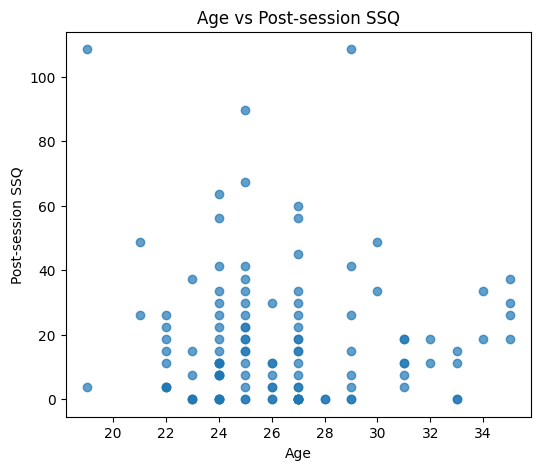

In [12]:
plt.figure(figsize=(6, 5))
plt.scatter(
    sessions["age"],
    sessions["post_ssq_total"],
    alpha=0.7
)
plt.xlabel("Age")
plt.ylabel("Post-session SSQ")
plt.title("Age vs Post-session SSQ")
plt.show()

<Figure size 700x500 with 0 Axes>

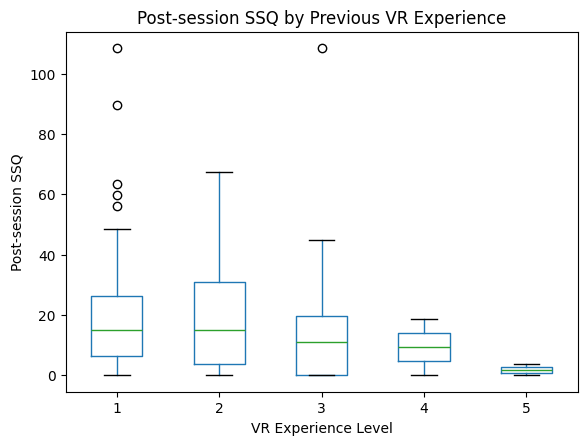

In [13]:
plt.figure(figsize=(7, 5))
sessions.boxplot(
    column="post_ssq_total",
    by="vr_experience",
    grid=False
)
plt.title("Post-session SSQ by Previous VR Experience")
plt.suptitle("")
plt.xlabel("VR Experience Level")
plt.ylabel("Post-session SSQ")
plt.show()

<Figure size 700x500 with 0 Axes>

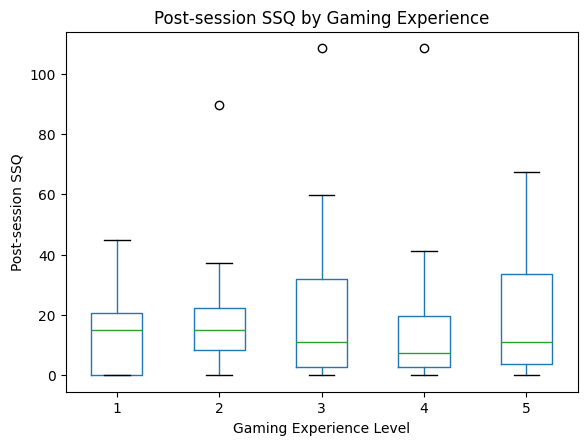

In [14]:
plt.figure(figsize=(7, 5))
sessions.boxplot(
    column="post_ssq_total",
    by="gaming_experience",
    grid=False
)
plt.title("Post-session SSQ by Gaming Experience")
plt.suptitle("")
plt.xlabel("Gaming Experience Level")
plt.ylabel("Post-session SSQ")
plt.show()

### Findings: Demographics and Experience

- Age shows almost no linear association with post-session or delta SSQ.
- Previous VR experience also shows only a weak relationship with cybersickness.
- Previous gaming experience does not show a clear monotonic relationship with SSQ.
- Male participants have somewhat higher average post-session and delta SSQ than female participants in this sample, but this descriptive difference should not be interpreted causally without controlling for game, order, and other factors.
- The highest VR-experience categories contain very few observations, so their apparently lower sickness scores are not reliable evidence of a protective effect.
- Overall, demographic and experience variables appear weaker than game and session-context effects and should likely be treated as supporting rather than dominant predictors.

## 6. Movement Feature Exploration

We now examine the early head-movement features extracted from the first 1, 3, and 5 minutes of each session.

The goals are to:

- understand the distribution and scale of movement features,
- identify remaining outliers or unusual sessions,
- determine how movement differs across games,
- examine how movement evolves across observation windows,
- and identify movement characteristics that may be associated with cybersickness.

This section will directly guide the next feature-engineering stage.

In [15]:
robust_movement_features = [
    "head_total_distance",
    "head_net_displacement",
    "head_velocity_mean",
    "head_velocity_std",
    "head_velocity_p95",
    "head_acceleration_mean",
    "head_acceleration_std",
    "head_acceleration_p95",
    "head_jerk_mean",
    "head_jerk_std",
    "head_jerk_p95",
    "head_total_rotation_rad",
    "head_angular_velocity_mean",
    "head_angular_velocity_std",
    "head_angular_velocity_p95"
]

print("Movement feature summary:")
display(
    movement[robust_movement_features]
    .describe()
    .T
    .round(3)
)

Movement feature summary:


,count,mean,std,min,25%,50%,75%,max
head_total_distance,360.0,15.873,13.869,0.626,4.772,12.103,23.324,79.128
head_net_displacement,360.0,0.298,0.292,0.011,0.087,0.211,0.389,1.718
head_velocity_mean,360.0,0.083,0.047,0.010,0.047,0.076,0.109,0.264
head_velocity_std,360.0,0.098,0.050,0.016,0.057,0.091,0.134,0.251
head_velocity_p95,360.0,0.271,0.141,0.033,0.162,0.254,0.358,0.755
head_acceleration_mean,360.0,0.378,0.193,0.082,0.234,0.340,0.484,1.059
head_acceleration_std,360.0,0.540,0.282,0.099,0.324,0.502,0.697,2.351
head_acceleration_p95,360.0,1.336,0.678,0.237,0.842,1.231,1.711,3.676
head_jerk_mean,360.0,14.532,7.385,3.089,8.751,13.278,18.439,41.412
head_jerk_std,360.0,22.179,12.532,3.871,13.013,20.529,29.229,115.047


In [16]:
window_summary = (
    movement.groupby("window")[robust_movement_features]
    .mean()
    .round(3)
)

display(window_summary)

,head_total_distance,head_net_displacement,head_velocity_mean,head_velocity_std,head_velocity_p95,head_acceleration_mean,head_acceleration_std,head_acceleration_p95,head_jerk_mean,head_jerk_std,head_jerk_p95,head_total_rotation_rad,head_angular_velocity_mean,head_angular_velocity_std,head_angular_velocity_p95
window,,,,,,,,,,,,,,,
1min,4.189,0.195,0.070,0.080,0.226,0.330,0.453,1.150,12.661,18.428,45.115,18.836,0.317,0.396,1.074
3min,15.646,0.329,0.087,0.105,0.287,0.392,0.563,1.397,15.051,23.009,54.878,62.260,0.347,0.459,1.217
5min,27.783,0.371,0.093,0.110,0.301,0.413,0.603,1.462,15.885,25.100,57.722,107.602,0.359,0.483,1.263


In [17]:
game_movement_summary = (
    movement.groupby(["window", "game_name"])[
        [
            "head_total_distance",
            "head_velocity_mean",
            "head_acceleration_mean",
            "head_total_rotation_rad",
            "head_angular_velocity_mean"
        ]
    ]
    .mean()
    .round(3)
)

display(game_movement_summary)

head_total_distance  head_velocity_mean  \
window game_name                                                     
1min   Beat Saber                        6.335               0.106   
       Cooking Simulator                 3.304               0.057   
       Forklift Simulator                2.206               0.037   
       Medal of Honor                    4.913               0.082   
3min   Beat Saber                       22.815               0.127   
       Cooking Simulator                16.716               0.094   
       Forklift Simulator                6.983               0.039   
       Medal of Honor                   16.069               0.089   
5min   Beat Saber                       41.527               0.138   
       Cooking Simulator                30.143               0.101   
       Forklift Simulator               11.333               0.038   
       Medal of Honor                   28.128               0.094   

                           head_acceleration_mean  head_total_rotation_rad  \
window game_name                                                             
1min   Beat Saber                           0.495                   16.693   
       Cooking Simulator                    0.264                   19.400   
       Forklift Simulator                   0.197                   12.856   
       Medal of Honor                       0.363                   26.395   
3min   Beat Saber                           0.563                   52.327   
       Cooking Simulator                    0.404                   71.596   
       Forklift Simulator                   0.206                   40.221   
       Medal of Honor                       0.394                   84.894   
5min   Beat Saber                           0.602                   97.416   
       Cooking Simulator                    0.433                  121.537   
       Forklift Simulator                   0.203                   66.309   
       Medal of Honor                       0.414                  145.146   

                           head_angular_velocity_mean  
window game_name                                       
1min   Beat Saber                               0.278  
       Cooking Simulator                        0.335  
       Forklift Simulator                       0.216  
       Medal of Honor                           0.440  
3min   Beat Saber                               0.291  
       Cooking Simulator                        0.402  
       Forklift Simulator                       0.224  
       Medal of Honor                           0.472  
5min   Beat Saber                               0.325  
       Cooking Simulator                        0.407  
       Forklift Simulator                       0.221  
       Medal of Honor                           0.484

<Figure size 900x500 with 0 Axes>

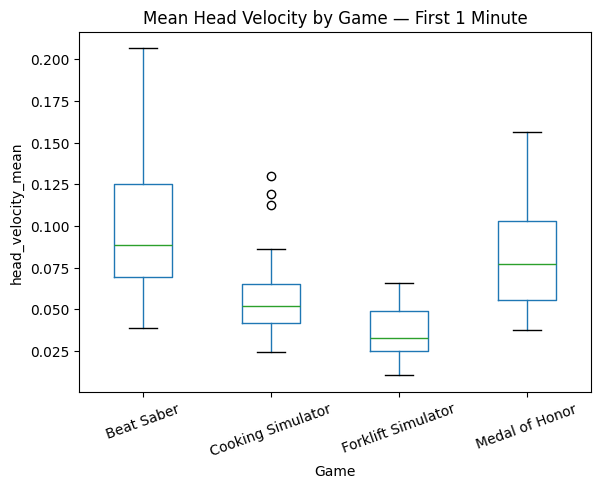

<Figure size 900x500 with 0 Axes>

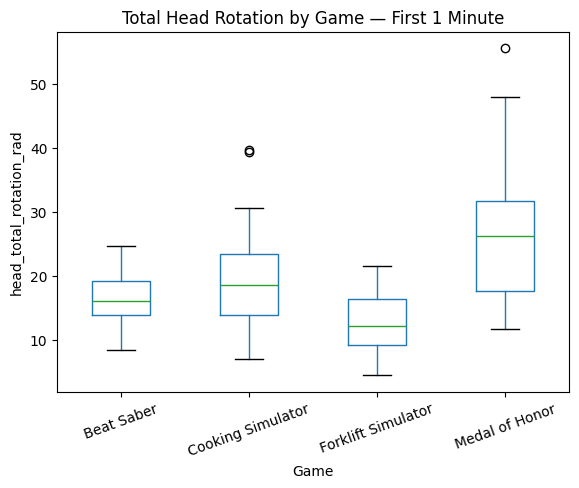

<Figure size 900x500 with 0 Axes>

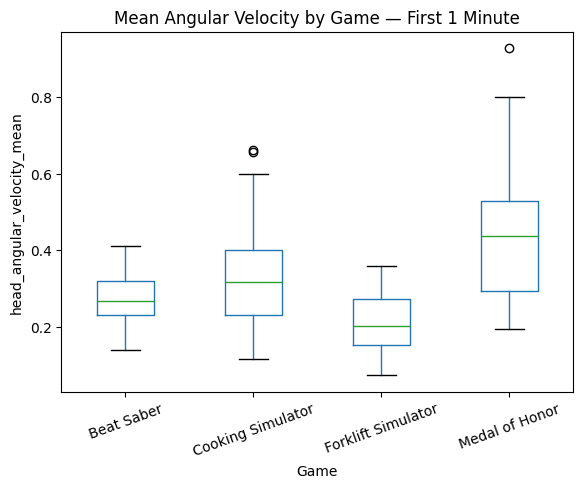

In [18]:
m1 = movement[movement["window"] == "1min"].copy()

for feature, title in [
    ("head_velocity_mean", "Mean Head Velocity"),
    ("head_total_rotation_rad", "Total Head Rotation"),
    ("head_angular_velocity_mean", "Mean Angular Velocity")
]:
    plt.figure(figsize=(9, 5))
    m1.boxplot(
        column=feature,
        by="game_name",
        grid=False,
        rot=20
    )
    plt.title(f"{title} by Game — First 1 Minute")
    plt.suptitle("")
    plt.xlabel("Game")
    plt.ylabel(feature)
    plt.show()

### Findings: Movement Characteristics

- Head-movement behavior differs substantially across the four VR games.
- Beat Saber produces relatively high translational head movement but comparatively low cybersickness.
- Medal of Honor produces the highest rotational movement, yet it does not produce the highest SSQ scores.
- Cooking Simulator produces the highest cybersickness despite only moderate head-movement intensity.
- Forklift Simulator contains relatively little head movement but still produces substantial cybersickness.
- Therefore, cybersickness cannot be explained by overall movement magnitude alone.
- Game-specific visual motion, locomotion mechanics, and interactions between movement and virtual motion may be important.
- Cumulative features such as total distance and total rotation naturally increase with observation-window duration, while normalized features such as mean velocity and angular velocity are more appropriate for comparing 1-, 3-, and 5-minute windows.
- Movement–sickness relationships should therefore be examined both overall and separately within each game to avoid confounding by game identity.

## 7. Movement–Cybersickness Relationships

The previous analysis showed that both movement behavior and cybersickness vary substantially across games.

Therefore, a correlation calculated across all games may be misleading. For example, a game may produce high movement but low sickness, while another produces low movement but high sickness.

We examine movement–SSQ relationships:

1. across the complete dataset,
2. separately for each observation window,
3. separately within each game.

Both Pearson and Spearman correlations are considered. Spearman correlation is particularly useful because SSQ distributions are strongly skewed and contain extreme observations.

In [19]:
correlation_features = [
    "head_velocity_mean",
    "head_velocity_std",
    "head_velocity_p95",
    "head_acceleration_mean",
    "head_acceleration_std",
    "head_acceleration_p95",
    "head_jerk_mean",
    "head_jerk_std",
    "head_jerk_p95",
    "head_angular_velocity_mean",
    "head_angular_velocity_std",
    "head_angular_velocity_p95"
]

targets = [
    "post_ssq_total",
    "delta_ssq_total"
]

for window in ["1min", "3min", "5min"]:
    temp = movement[movement["window"] == window]

    print("\n" + "=" * 70)
    print(f"{window} — Spearman correlations")
    print("=" * 70)

    corr = (
        temp[correlation_features + targets]
        .corr(method="spearman")
        .loc[correlation_features, targets]
        .round(3)
    )

    display(
        corr.sort_values(
            "post_ssq_total",
            key=abs,
            ascending=False
        )
    )


1min — Spearman correlations


,post_ssq_total,delta_ssq_total
head_angular_velocity_p95,0.214,0.212
head_angular_velocity_std,0.202,0.210
head_acceleration_mean,-0.127,-0.167
head_jerk_mean,-0.127,-0.167
head_velocity_mean,-0.118,-0.149
head_jerk_std,-0.116,-0.150
head_angular_velocity_mean,0.108,0.076
head_velocity_std,-0.107,-0.119
head_acceleration_std,-0.104,-0.139
head_acceleration_p95,-0.102,-0.141



3min — Spearman correlations


,post_ssq_total,delta_ssq_total
head_angular_velocity_p95,0.183,0.193
head_angular_velocity_std,0.174,0.192
head_velocity_std,-0.152,-0.134
head_jerk_std,-0.150,-0.142
head_acceleration_std,-0.142,-0.133
head_jerk_mean,-0.141,-0.141
head_acceleration_mean,-0.140,-0.141
head_velocity_mean,-0.137,-0.132
head_jerk_p95,-0.132,-0.131
head_angular_velocity_mean,0.123,0.111



5min — Spearman correlations


,post_ssq_total,delta_ssq_total
head_angular_velocity_std,0.173,0.168
head_angular_velocity_p95,0.166,0.164
head_jerk_mean,-0.122,-0.127
head_jerk_std,-0.112,-0.108
head_acceleration_mean,-0.110,-0.116
head_velocity_mean,-0.109,-0.108
head_velocity_std,-0.108,-0.097
head_jerk_p95,-0.105,-0.107
head_angular_velocity_mean,0.105,0.076
head_acceleration_std,-0.101,-0.096


In [20]:
for window in ["1min", "3min", "5min"]:

    print("\n" + "=" * 80)
    print(f"WITHIN-GAME CORRELATIONS — {window}")
    print("=" * 80)

    temp = movement[movement["window"] == window]

    for game in sorted(temp["game_name"].unique()):

        g = temp[temp["game_name"] == game]

        corr = (
            g[correlation_features + targets]
            .corr(method="spearman")
            .loc[correlation_features, targets]
        )

        print(f"\n{game}")

        display(
            corr.sort_values(
                "post_ssq_total",
                key=abs,
                ascending=False
            )
            .head(6)
            .round(3)
        )


WITHIN-GAME CORRELATIONS — 1min

Beat Saber


,post_ssq_total,delta_ssq_total
head_angular_velocity_p95,0.308,0.170
head_angular_velocity_std,0.256,0.153
head_angular_velocity_mean,0.249,0.156
head_velocity_std,0.112,0.266
head_acceleration_std,0.105,0.284
head_jerk_mean,0.102,0.223



Cooking Simulator


,post_ssq_total,delta_ssq_total
head_angular_velocity_p95,0.130,0.094
head_angular_velocity_mean,0.090,0.057
head_acceleration_std,0.080,0.011
head_angular_velocity_std,0.067,0.033
head_velocity_std,0.049,0.003
head_acceleration_mean,-0.033,-0.082



Forklift Simulator


,post_ssq_total,delta_ssq_total
head_velocity_mean,0.370,0.418
head_acceleration_mean,0.362,0.432
head_jerk_mean,0.358,0.407
head_acceleration_p95,0.322,0.390
head_velocity_p95,0.320,0.386
head_jerk_p95,0.309,0.372


... (14 outputs left out)


Forklift Simulator


,post_ssq_total,delta_ssq_total
head_acceleration_mean,0.368,0.418
head_velocity_mean,0.354,0.411
head_acceleration_p95,0.334,0.379
head_jerk_mean,0.331,0.371
head_angular_velocity_mean,0.323,0.393
head_jerk_p95,0.309,0.369



Medal of Honor


,post_ssq_total,delta_ssq_total
head_angular_velocity_std,-0.136,-0.260
head_velocity_mean,0.103,-0.008
head_acceleration_mean,0.080,-0.010
head_jerk_mean,0.074,-0.021
head_jerk_p95,0.042,-0.058
head_jerk_std,-0.037,-0.077


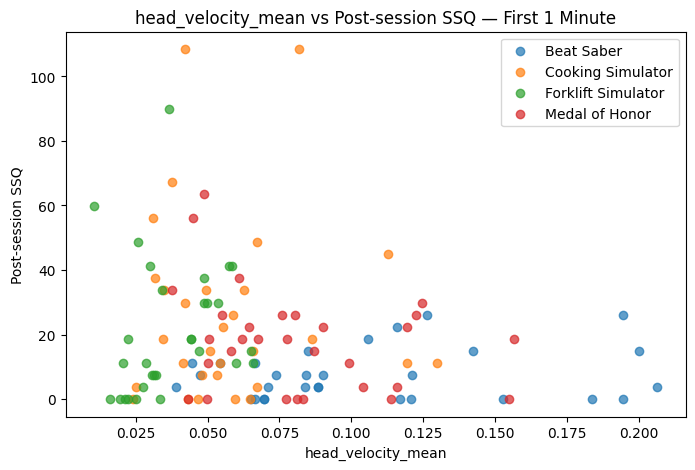

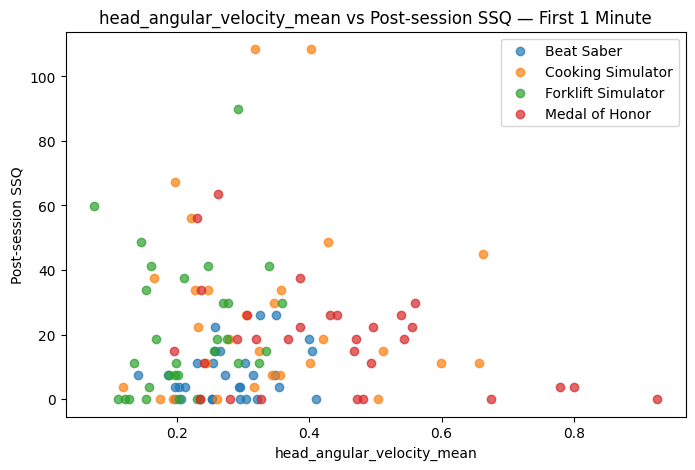

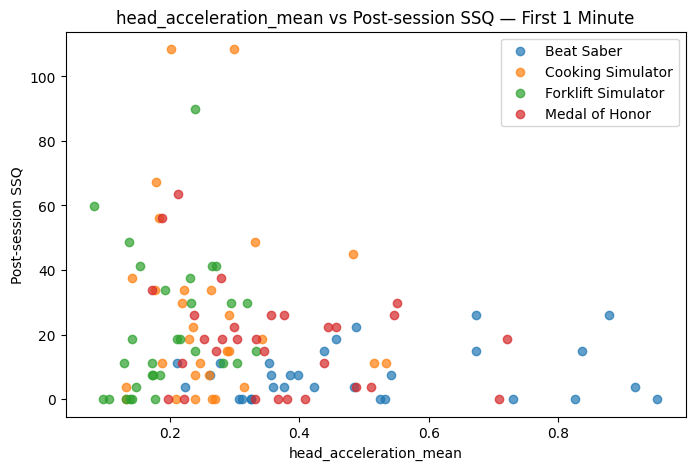

In [21]:
m1 = movement[movement["window"] == "1min"].copy()

features_to_plot = [
    "head_velocity_mean",
    "head_angular_velocity_mean",
    "head_acceleration_mean"
]

for feature in features_to_plot:

    plt.figure(figsize=(8, 5))

    for game in sorted(m1["game_name"].unique()):
        g = m1[m1["game_name"] == game]

        plt.scatter(
            g[feature],
            g["post_ssq_total"],
            alpha=0.7,
            label=game
        )

    plt.xlabel(feature)
    plt.ylabel("Post-session SSQ")
    plt.title(f"{feature} vs Post-session SSQ — First 1 Minute")
    plt.legend()
    plt.show()

### Findings: Movement–Cybersickness Relationships

- Across all games, individual movement features show only weak associations with cybersickness.
- Rotational variability, particularly angular-velocity standard deviation and upper-percentile angular velocity, shows the strongest overall relationship, although the correlations remain modest.
- The relationship between movement and cybersickness differs substantially by game.
- In Beat Saber, greater rotational activity tends to be associated with higher sickness scores, particularly at longer observation windows.
- In Forklift Simulator, several movement-intensity features show moderate positive associations with post-session and delta SSQ.
- In Cooking Simulator, several movement features show negative associations with sickness at the 3- and 5-minute windows.
- In Medal of Honor, early rotational variability is negatively associated with sickness, particularly for delta SSQ.
- These contrasting relationships indicate that movement features should not necessarily be interpreted independently of game context.
- Future feature engineering should therefore consider game–movement interactions, within-game normalization, and temporal movement patterns rather than relying only on global movement averages.
- Because each game contains only 30 sessions, these correlations are exploratory and should later be evaluated with appropriate uncertainty or significance analysis.

## 8. Temporal Evolution of Early Movement

Aggregating an entire observation window into a single mean or percentile may hide important temporal behavior.

For example, two users may have the same average head velocity over five minutes even if one remains stable while the other shows progressively increasing or decreasing motion.

This section examines how movement evolves over time and whether changes between early and later portions of the exposure may provide more informative features for cybersickness prediction.

In [22]:
temporal_features = [
    "head_velocity_mean",
    "head_velocity_std",
    "head_acceleration_mean",
    "head_angular_velocity_mean",
    "head_angular_velocity_std"
]

wide = movement.pivot(
    index=["participant_id", "session_number", "game_name"],
    columns="window",
    values=temporal_features
)

wide.columns = [
    f"{feature}_{window}"
    for feature, window in wide.columns
]

wide = wide.reset_index()

for feature in temporal_features:
    wide[f"{feature}_change_1_to_3"] = (
        wide[f"{feature}_3min"] -
        wide[f"{feature}_1min"]
    )

    wide[f"{feature}_change_3_to_5"] = (
        wide[f"{feature}_5min"] -
        wide[f"{feature}_3min"]
    )

    wide[f"{feature}_change_1_to_5"] = (
        wide[f"{feature}_5min"] -
        wide[f"{feature}_1min"]
    )

display(
    wide[
        [
            "participant_id",
            "session_number",
            "game_name"
        ]
        + [
            c for c in wide.columns
            if "change_" in c
        ]
    ].head()
)

,participant_id,session_number,game_name,head_velocity_mean_change_1_to_3,head_velocity_mean_change_3_to_5,head_velocity_mean_change_1_to_5,head_velocity_std_change_1_to_3,head_velocity_std_change_3_to_5,head_velocity_std_change_1_to_5,head_acceleration_mean_change_1_to_3,head_acceleration_mean_change_3_to_5,head_acceleration_mean_change_1_to_5,head_angular_velocity_mean_change_1_to_3,head_angular_velocity_mean_change_3_to_5,head_angular_velocity_mean_change_1_to_5,head_angular_velocity_std_change_1_to_3,head_angular_velocity_std_change_3_to_5,head_angular_velocity_std_change_1_to_5
0,group1_order1_user0,1,Cooking Simulator,0.015056,0.001035,0.016091,-0.011356,-0.004433,-0.015788,0.039338,0.008387,0.047725,0.021681,-0.000824,0.020857,-0.042569,0.050440,0.007871
1,group1_order1_user0,2,Beat Saber,0.041137,0.024491,0.065628,0.058906,0.010804,0.069710,0.162243,0.119001,0.281244,0.023424,0.071740,0.095164,0.006146,0.108766,0.114912
2,group1_order1_user1,1,Cooking Simulator,0.020718,-0.004106,0.016612,0.065658,0.001044,0.066702,0.123128,-0.043046,0.080082,-0.018744,-0.047302,-0.066045,0.143946,-0.042993,0.100953
3,group1_order1_user1,2,Beat Saber,0.019632,0.012199,0.031831,0.047592,0.002370,0.049962,0.103183,0.055037,0.158220,0.050294,0.013610,0.063904,0.102362,0.019043,0.121405
4,group1_order1_user10,1,Cooking Simulator,0.056088,0.001837,0.057925,0.125596,-0.006425,0.119171,0.214764,0.008096,0.222860,0.087185,0.018291,0.105476,0.139367,0.046138,0.185505


In [23]:
ssq_for_merge = sessions[
    [
        "participant_id",
        "session_number",
        "post_ssq_total",
        "delta_ssq_total"
    ]
]

temporal = wide.merge(
    ssq_for_merge,
    on=["participant_id", "session_number"],
    how="left"
)

In [24]:
change_cols = [
    c for c in temporal.columns
    if "change_" in c
]

print("Temporal-change correlations with SSQ:")

display(
    temporal[
        change_cols
        + ["post_ssq_total", "delta_ssq_total"]
    ]
    .corr(method="spearman")
    .loc[
        change_cols,
        ["post_ssq_total", "delta_ssq_total"]
    ]
    .sort_values(
        "post_ssq_total",
        key=abs,
        ascending=False
    )
    .round(3)
)

Temporal-change correlations with SSQ:


,post_ssq_total,delta_ssq_total
head_acceleration_mean_change_3_to_5,0.152,0.129
head_velocity_mean_change_3_to_5,0.134,0.116
head_angular_velocity_mean_change_3_to_5,0.123,0.081
head_velocity_std_change_1_to_3,-0.107,-0.108
head_angular_velocity_mean_change_1_to_5,0.097,0.083
head_velocity_std_change_3_to_5,0.091,0.086
head_angular_velocity_mean_change_1_to_3,0.084,0.093
head_angular_velocity_std_change_3_to_5,0.074,0.028
head_angular_velocity_std_change_1_to_5,0.070,0.024
head_acceleration_mean_change_1_to_5,0.053,0.050


In [25]:
for game in sorted(temporal["game_name"].unique()):

    g = temporal[
        temporal["game_name"] == game
    ]

    print("\n" + "=" * 70)
    print(game)
    print("=" * 70)

    corr = (
        g[
            change_cols
            + ["post_ssq_total", "delta_ssq_total"]
        ]
        .corr(method="spearman")
        .loc[
            change_cols,
            ["post_ssq_total", "delta_ssq_total"]
        ]
    )

    display(
        corr.sort_values(
            "post_ssq_total",
            key=abs,
            ascending=False
        )
        .head(10)
        .round(3)
    )


Beat Saber


,post_ssq_total,delta_ssq_total
head_acceleration_mean_change_3_to_5,0.263,0.070
head_velocity_mean_change_3_to_5,0.213,0.012
head_acceleration_mean_change_1_to_5,0.200,-0.017
head_velocity_mean_change_1_to_5,0.146,-0.040
head_velocity_std_change_1_to_3,0.139,0.049
head_angular_velocity_mean_change_3_to_5,0.128,-0.118
head_angular_velocity_mean_change_1_to_5,0.092,0.180
head_angular_velocity_std_change_1_to_5,0.080,0.114
head_velocity_std_change_1_to_5,0.080,-0.002
head_angular_velocity_std_change_1_to_3,-0.079,0.137



Cooking Simulator


,post_ssq_total,delta_ssq_total
head_angular_velocity_mean_change_1_to_3,-0.418,-0.381
head_acceleration_mean_change_1_to_3,-0.411,-0.346
head_velocity_std_change_1_to_3,-0.403,-0.375
head_velocity_mean_change_1_to_3,-0.376,-0.288
head_angular_velocity_std_change_1_to_3,-0.366,-0.388
head_angular_velocity_std_change_1_to_5,-0.353,-0.371
head_angular_velocity_mean_change_1_to_5,-0.306,-0.275
head_acceleration_mean_change_1_to_5,-0.288,-0.230
head_velocity_mean_change_1_to_5,-0.282,-0.218
head_velocity_std_change_3_to_5,0.266,0.233



Forklift Simulator


,post_ssq_total,delta_ssq_total
head_velocity_std_change_1_to_3,-0.216,-0.277
head_angular_velocity_std_change_1_to_5,0.128,0.058
head_acceleration_mean_change_1_to_3,-0.121,-0.174
head_angular_velocity_mean_change_3_to_5,0.115,0.064
head_angular_velocity_mean_change_1_to_5,0.113,0.006
head_velocity_mean_change_1_to_3,-0.100,-0.126
head_velocity_std_change_1_to_5,-0.074,-0.110
head_angular_velocity_std_change_3_to_5,0.074,0.050
head_acceleration_mean_change_1_to_5,-0.067,-0.138
head_velocity_std_change_3_to_5,0.060,0.109



Medal of Honor


,post_ssq_total,delta_ssq_total
head_angular_velocity_std_change_3_to_5,0.473,0.515
head_angular_velocity_std_change_1_to_5,0.420,0.321
head_angular_velocity_mean_change_1_to_5,0.413,0.372
head_velocity_mean_change_3_to_5,0.411,0.453
head_acceleration_mean_change_1_to_5,0.401,0.357
head_velocity_mean_change_1_to_5,0.400,0.354
head_acceleration_mean_change_3_to_5,0.374,0.404
head_angular_velocity_mean_change_3_to_5,0.359,0.456
head_angular_velocity_std_change_1_to_3,0.323,0.177
head_angular_velocity_mean_change_1_to_3,0.307,0.221


### Findings: Temporal Changes

- When all games are pooled together, changes between the 1-, 3-, and 5-minute movement summaries show only weak correlations with cybersickness.
- However, substantially stronger relationships appear when the analysis is performed separately by game.
- In Cooking Simulator, increases in several movement features between minutes 1 and 3 are negatively associated with post-session and delta SSQ.
- In Medal of Honor, increases in rotational variability and movement intensity between minutes 3 and 5 show moderate-to-strong positive associations with cybersickness. The strongest observed relationship is between the change in angular-velocity variability from 3 to 5 minutes and delta SSQ.
- Beat Saber shows weaker positive temporal relationships, particularly for changes in acceleration later in the observation period.
- Forklift Simulator shows relatively weak temporal-change relationships, suggesting that absolute movement intensity may be more informative than temporal evolution for this game.
- These results indicate that temporal movement features may be useful, but their meaning depends strongly on game context.
- Future feature engineering should therefore include game–temporal interactions and finer-grained movement trajectories rather than relying only on global changes between the 1-, 3-, and 5-minute windows.

## 9. Movement Feature Redundancy

Many movement features are mathematically related. For example, mean velocity, velocity percentiles, acceleration, and jerk may contain overlapping information.

Highly redundant features can:

- make interpretation difficult,
- increase model variance,
- and provide little additional predictive information.

We therefore examine correlations among the current movement features before designing the next feature set.

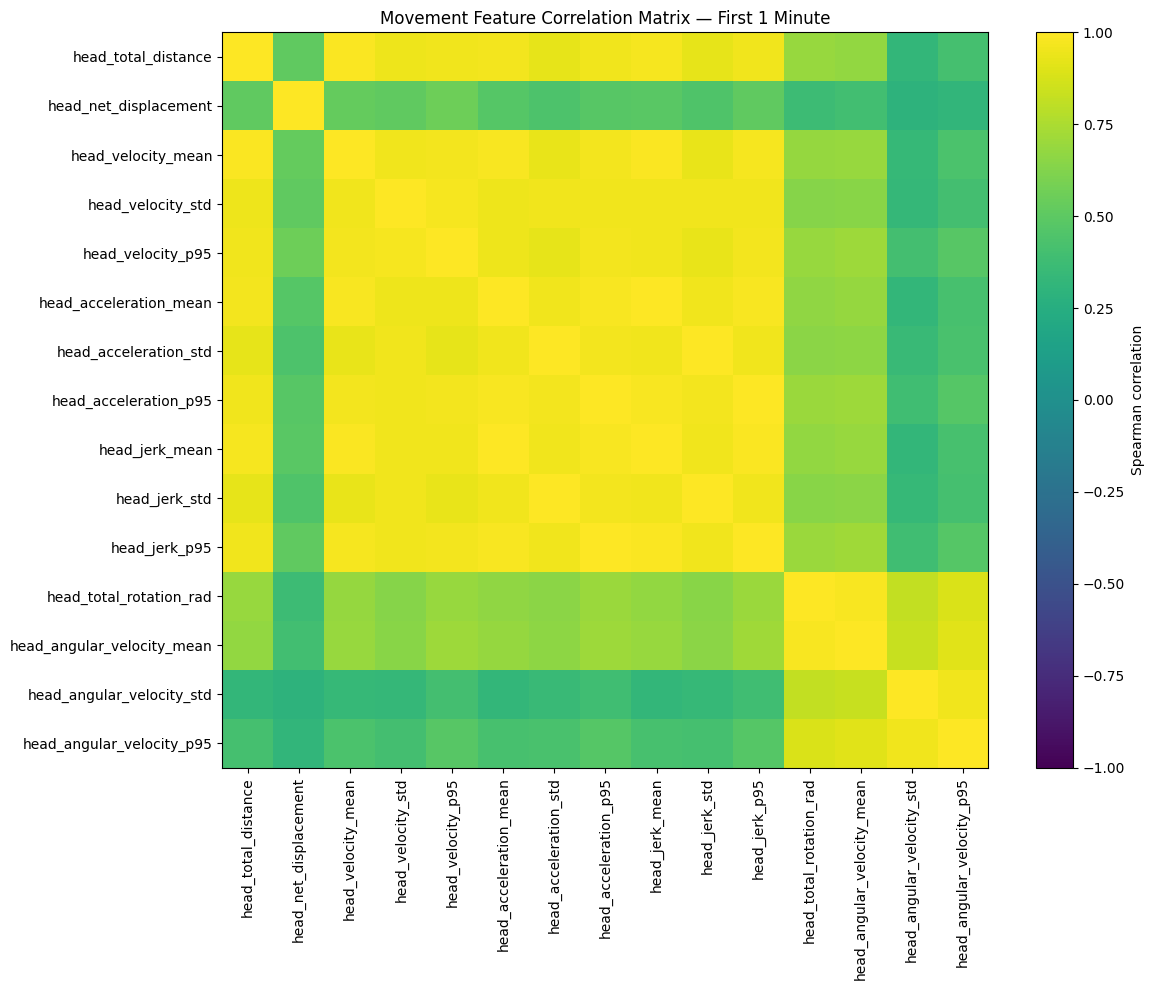

In [26]:
m1 = movement[movement["window"] == "1min"].copy()

feature_corr = (
    m1[robust_movement_features]
    .corr(method="spearman")
)

plt.figure(figsize=(12, 10))
plt.imshow(
    feature_corr,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Spearman correlation")

plt.xticks(
    range(len(feature_corr.columns)),
    feature_corr.columns,
    rotation=90
)

plt.yticks(
    range(len(feature_corr.index)),
    feature_corr.index
)

plt.title("Movement Feature Correlation Matrix — First 1 Minute")
plt.tight_layout()
plt.show()

In [27]:
high_corr_pairs = []

cols = feature_corr.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = feature_corr.iloc[i, j]

        if abs(r) >= 0.90:
            high_corr_pairs.append(
                {
                    "feature_1": cols[i],
                    "feature_2": cols[j],
                    "spearman_r": r
                }
            )

high_corr_df = pd.DataFrame(high_corr_pairs)

display(
    high_corr_df
    .sort_values(
        "spearman_r",
        key=abs,
        ascending=False
    )
    .round(3)
)

,feature_1,feature_2,spearman_r
32,head_acceleration_mean,head_jerk_mean,0.996
37,head_acceleration_std,head_jerk_std,0.993
41,head_acceleration_p95,head_jerk_p95,0.993
0,head_total_distance,head_velocity_mean,0.987
43,head_jerk_mean,head_jerk_p95,0.987
14,head_velocity_mean,head_jerk_mean,0.986
31,head_acceleration_mean,head_acceleration_p95,0.983
34,head_acceleration_mean,head_jerk_p95,0.983
45,head_total_rotation_rad,head_angular_velocity_mean,0.982
39,head_acceleration_p95,head_jerk_mean,0.982


### Findings: Movement Feature Redundancy

- The current movement feature set contains substantial multicollinearity.
- Mean acceleration and mean jerk are almost perfectly correlated.
- Acceleration and jerk variability and percentile features are also highly redundant.
- Mean velocity, velocity percentiles, acceleration, and jerk features form a strongly correlated group.
- Total head distance is highly correlated with mean head velocity because both describe translational movement over a fixed observation interval.
- Total rotation is similarly highly correlated with mean angular velocity.
- Angular-velocity standard deviation and upper-percentile angular velocity are also strongly related.

These results indicate that simply adding more aggregate statistics is unlikely to improve prediction. Future feature engineering should prioritize qualitatively different information rather than multiple mathematical transformations of the same movement signal.

A reduced set of representative features should be preferred before modeling.

## 10. EDA Conclusions and Feature-Engineering Hypotheses

The exploratory analysis suggests that cybersickness prediction is not a simple function of overall head-movement magnitude.

The main findings are:

1. SSQ outcomes are strongly skewed and contain several extreme cases.
2. Game identity is strongly associated with cybersickness.
3. Game speed is confounded with game identity and should not be interpreted independently.
4. Participant sickness is only weakly consistent between sessions.
5. Session order and possible adaptation/carryover effects appear important.
6. Demographic and experience variables show relatively weak associations with sickness.
7. Movement behavior differs strongly across games.
8. Global movement–SSQ correlations are weak.
9. Stronger movement–SSQ relationships appear within individual games.
10. Temporal movement changes are also game dependent.
11. The current aggregate movement features are highly redundant.

These findings motivate a second feature-engineering stage focused on temporal structure, movement patterns, game interactions, and reduced redundancy.

### Proposed Second-Generation Features

| Feature family | Examples | Motivation |
|---|---|---|
| Reduced base motion | velocity mean/std, angular velocity mean/std | Remove redundant acceleration/jerk copies |
| Short-window temporal features | statistics for each 60-second block | Preserve temporal evolution |
| Trend features | slope across minute blocks | Detect increasing/decreasing movement |
| Movement bursts | number/duration of high-motion periods | Capture episodic movement |
| Stationary behavior | fraction of time near stationary | Possible sickness-related movement suppression |
| Rapid head turns | count above angular-velocity threshold | Literature-supported rotational exposure |
| Rotation variability | angular velocity variability and upper percentiles | Strongest current global movement relationship |
| Directional rotation | yaw, pitch, roll separately | Current quaternion magnitude hides direction |
| Motion-state transitions | stationary → active and active → stationary counts | Capture behavioral changes |
| Within-game normalization | movement relative to typical behavior for that game | Remove game-specific movement scale |
| Game × movement interactions | game with rotation/velocity/trend features | EDA shows opposite relationships across games |
| Session/order context | session number, order, previous exposure | Account for carryover/adaptation |

## 11. Fine-Grained Temporal Movement Analysis

The previous analysis showed that broad 1-, 3-, and 5-minute summaries can hide important temporal behavior.

We now divide the first 5 minutes of each session into consecutive 60-second blocks:

- 0–60 s
- 60–120 s
- 120–180 s
- 180–240 s
- 240–300 s

For each block, we examine translational and rotational movement separately. This allows us to study whether movement increases, decreases, or becomes more variable over time, and whether those patterns differ according to cybersickness level and game.

In [28]:
from pathlib import Path

RAW_MOVEMENT_DIR = Path("../data/raw/Questset/movement")

block_rows = []

for _, session in sessions.iterrows():

    filename = Path(session["movement_filepath"]).name
    path = RAW_MOVEMENT_DIR / filename

    df = pd.read_csv(path)

    # first 5 minutes only
    df = df[df["time"] <= 300].copy()

    for block_start in [0, 60, 120, 180, 240]:

        block_end = block_start + 60

        b = df[
            (df["time"] >= block_start) &
            (df["time"] < block_end)
        ].copy()

        if len(b) < 2:
            continue

        time = b["time"].to_numpy()

        pos = b[
            ["HeadPosX", "HeadPosY", "HeadPosZ"]
        ].to_numpy(float)

        dt = np.diff(time)

        displacement = np.diff(pos, axis=0)
        distance_step = np.linalg.norm(displacement, axis=1)

        valid = (
            (dt > 0)
            & (distance_step <= 0.10)
        )

        velocity = np.full(len(distance_step), np.nan)
        velocity[valid] = (
            distance_step[valid] /
            dt[valid]
        )

        quat = b[
            [
                "HeadOrientationW",
                "HeadOrientationX",
                "HeadOrientationY",
                "HeadOrientationZ"
            ]
        ].to_numpy(float)

        norms = np.linalg.norm(quat, axis=1)

        good = norms > 0
        quat[good] = quat[good] / norms[good, None]

        q1 = quat[:-1]
        q2 = quat[1:]

        dots = np.abs(
            np.sum(q1 * q2, axis=1)
        )

        dots = np.clip(
            dots,
            -1.0,
            1.0
        )

        angular_change = (
            2 * np.arccos(dots)
        )

        angular_velocity = np.full(
            len(angular_change),
            np.nan
        )

        angular_velocity[dt > 0] = (
            angular_change[dt > 0] /
            dt[dt > 0]
        )

        block_rows.append(
            {
                "participant_id":
                    session["participant_id"],

                "session_number":
                    session["session_number"],

                "game_name":
                    session["game_name"],

                "block":
                    f"{block_start}-{block_end}",

                "block_start":
                    block_start,

                "velocity_mean":
                    np.nanmean(velocity),

                "velocity_std":
                    np.nanstd(velocity),

                "angular_velocity_mean":
                    np.nanmean(angular_velocity),

                "angular_velocity_std":
                    np.nanstd(angular_velocity),

                "post_ssq_total":
                    session["post_ssq_total"],

                "delta_ssq_total":
                    session["delta_ssq_total"]
            }
        )

blocks = pd.DataFrame(block_rows)

print("Rows:", len(blocks))
print("Sessions:", blocks[
    ["participant_id", "session_number"]
].drop_duplicates().shape[0])

print("\nRows per block:")
print(blocks["block"].value_counts().sort_index())

Rows: 600
Sessions: 120

Rows per block:
block
0-60       120
120-180    120
180-240    120
240-300    120
60-120     120
Name: count, dtype: int64


### Average Movement Across Time Blocks

We first examine whether the average movement pattern changes across the first five minutes of exposure.

In [29]:
block_summary = (
    blocks.groupby("block")[
        [
            "velocity_mean",
            "velocity_std",
            "angular_velocity_mean",
            "angular_velocity_std"
        ]
    ]
    .mean()
    .round(3)
)

display(block_summary)

,velocity_mean,velocity_std,angular_velocity_mean,angular_velocity_std
block,,,,
0-60,0.071,0.080,0.319,0.399
120-180,0.086,0.095,0.351,0.459
180-240,0.113,0.116,0.389,0.488
240-300,0.090,0.097,0.369,0.487
60-120,0.106,0.118,0.375,0.476


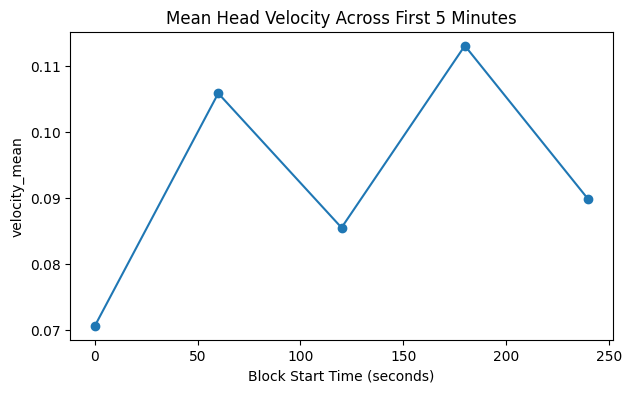

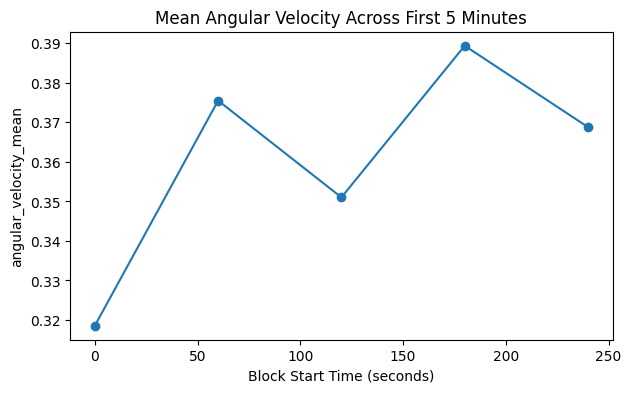

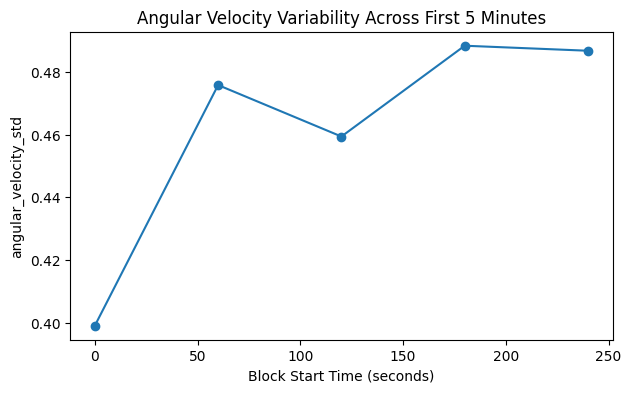

In [30]:
for feature, title in [
    ("velocity_mean", "Mean Head Velocity"),
    ("angular_velocity_mean", "Mean Angular Velocity"),
    ("angular_velocity_std", "Angular Velocity Variability")
]:

    temp = (
        blocks.groupby("block_start")[feature]
        .mean()
    )

    plt.figure(figsize=(7, 4))

    plt.plot(
        temp.index,
        temp.values,
        marker="o"
    )

    plt.xlabel("Block Start Time (seconds)")
    plt.ylabel(feature)
    plt.title(f"{title} Across First 5 Minutes")
    plt.show()

### Temporal Movement by Game and Sickness Level

The pooled temporal trajectories may hide important game-specific behavior.

We therefore examine the 60-second movement blocks separately by game and compare sessions with relatively low and high cybersickness.

This helps determine whether high-sickness sessions show different movement trajectories, such as increasing rotation, decreasing motion, or greater variability over time.

In [31]:
# Define low/high sickness using the median post-session SSQ
median_post_ssq = sessions["post_ssq_total"].median()

blocks["sickness_group"] = np.where(
    blocks["post_ssq_total"] > median_post_ssq,
    "High",
    "Low"
)

print("Median post-SSQ threshold:", median_post_ssq)

print("\nSession counts by sickness group:")
display(
    blocks[
        ["participant_id", "session_number", "sickness_group"]
    ]
    .drop_duplicates()
    ["sickness_group"]
    .value_counts()
)

Median post-SSQ threshold: 11.22

Session counts by sickness group:


sickness_group
Low     61
High    59
Name: count, dtype: int64

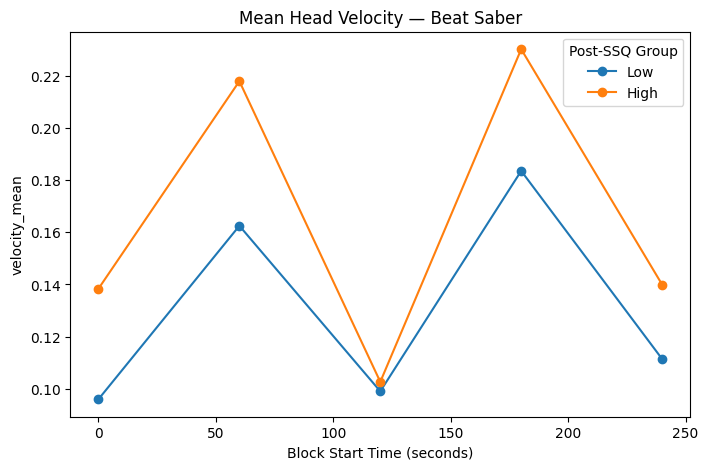

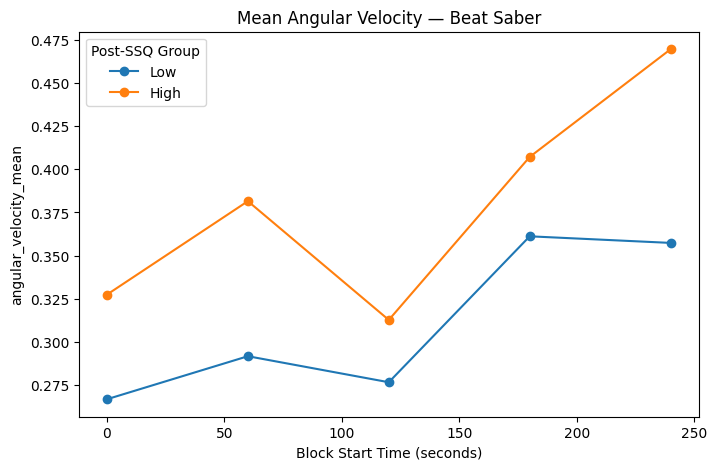

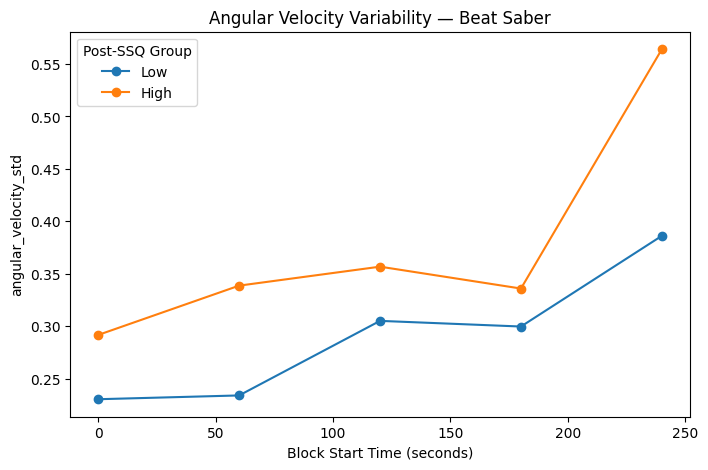

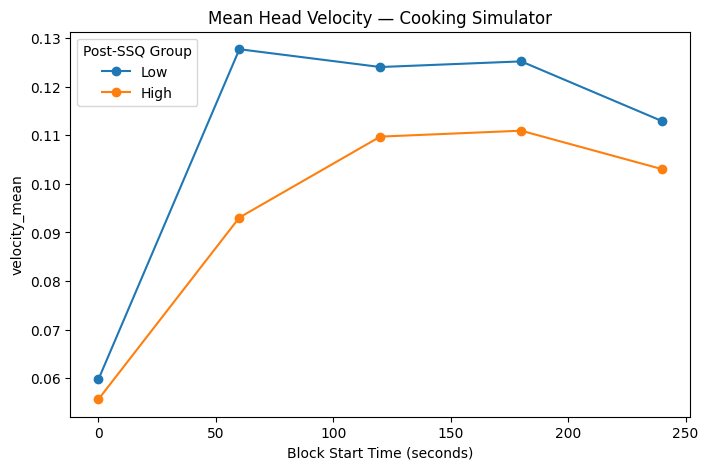

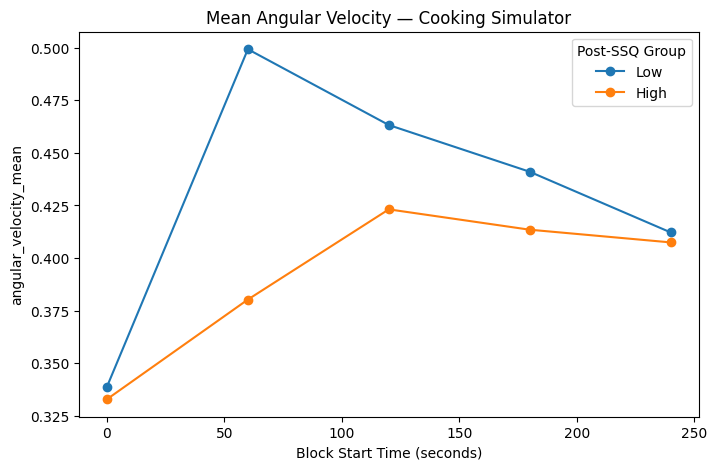

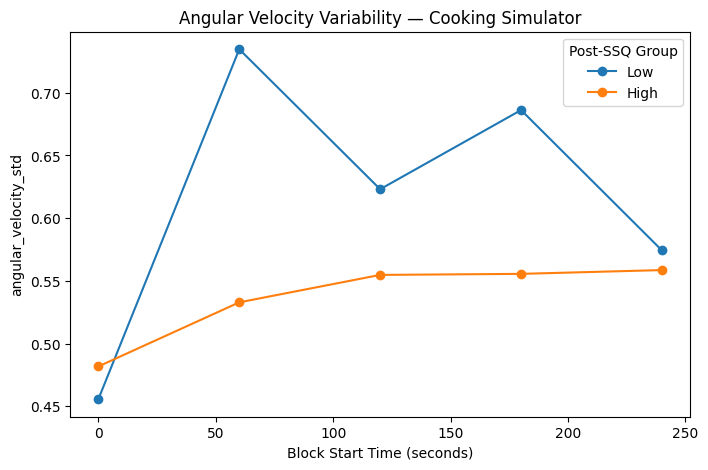

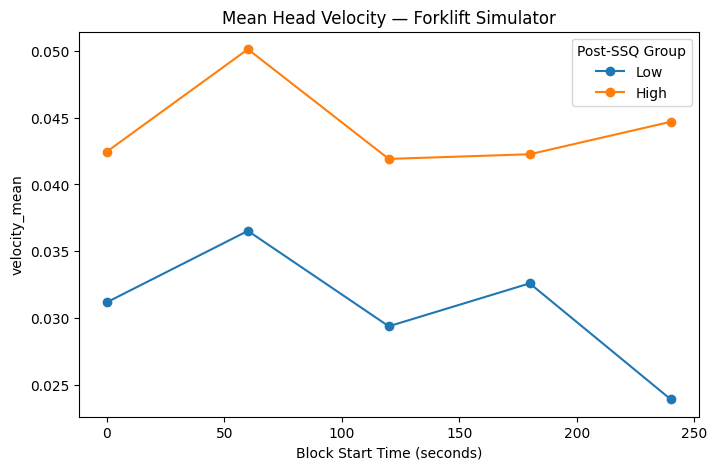

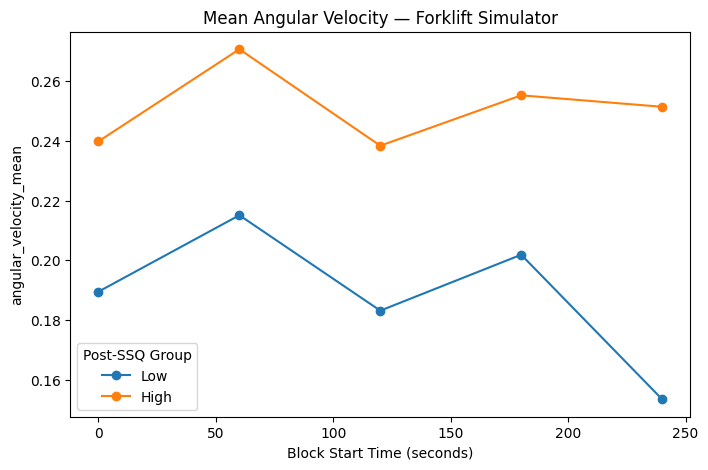

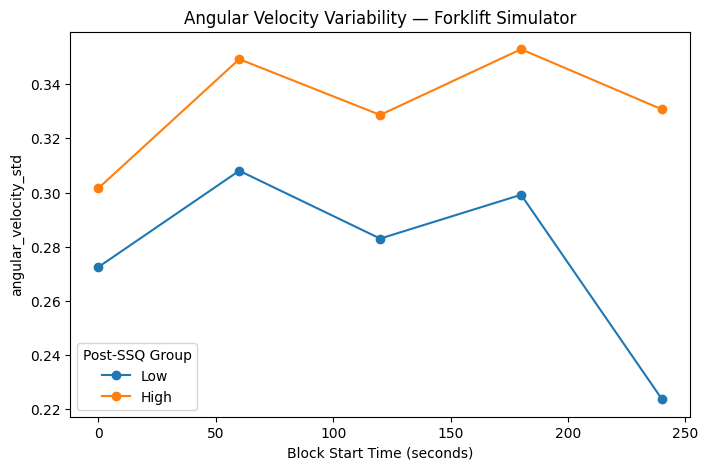

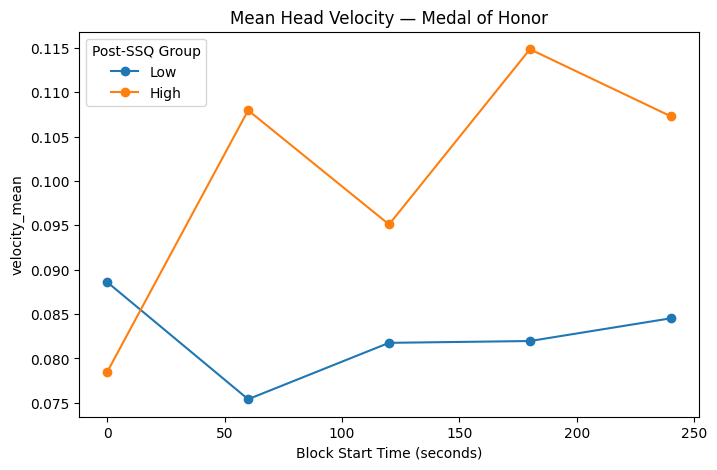

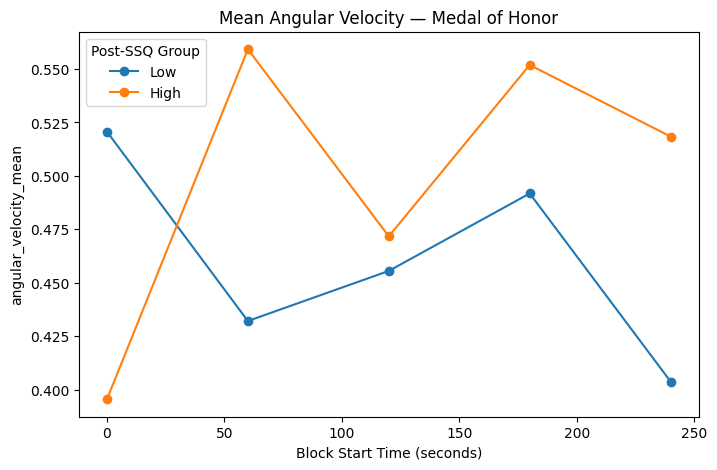

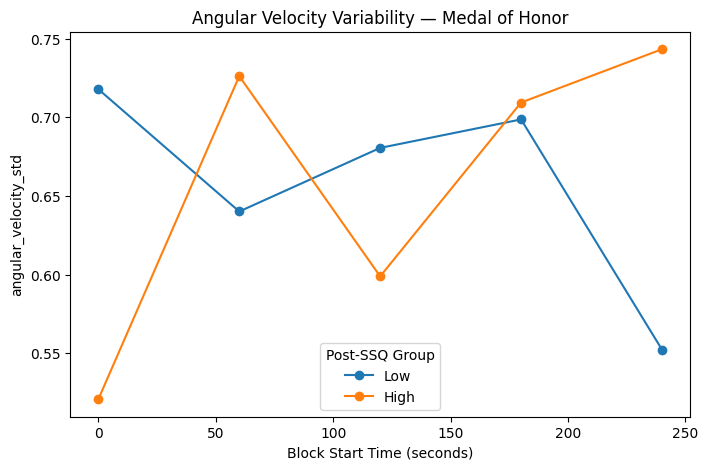

In [32]:
features_to_plot = [
    ("velocity_mean", "Mean Head Velocity"),
    ("angular_velocity_mean", "Mean Angular Velocity"),
    ("angular_velocity_std", "Angular Velocity Variability")
]

for game in sorted(blocks["game_name"].unique()):

    g = blocks[blocks["game_name"] == game]

    for feature, title in features_to_plot:

        plt.figure(figsize=(8, 5))

        for sickness_group in ["Low", "High"]:

            temp = (
                g[g["sickness_group"] == sickness_group]
                .groupby("block_start")[feature]
                .mean()
            )

            plt.plot(
                temp.index,
                temp.values,
                marker="o",
                label=sickness_group
            )

        plt.xlabel("Block Start Time (seconds)")
        plt.ylabel(feature)
        plt.title(f"{title} — {game}")
        plt.legend(title="Post-SSQ Group")
        plt.show()

### Findings: Game-Specific Temporal Trajectories

- Fine-grained 60-second analysis reveals substantially stronger patterns than pooled global averages.
- Beat Saber high-sickness sessions generally show greater translational and rotational movement, with the separation becoming stronger later in the exposure.
- Cooking Simulator shows the opposite pattern: high-sickness sessions tend to exhibit less movement than low-sickness sessions across much of the first five minutes.
- Forklift Simulator shows relatively stable separation, with high-sickness sessions displaying greater movement intensity and rotational variability throughout the exposure.
- Medal of Honor shows a strong late-session divergence, where high-sickness sessions increasingly exceed low-sickness sessions in translational movement, angular velocity, and rotational variability.
- These findings reinforce that the relationship between movement and cybersickness is strongly game dependent.
- Future feature engineering should include game-specific temporal trends and interactions rather than assuming one universal movement–sickness relationship.

## 12. Candidate Temporal Feature Construction

Based on the EDA, we now quantify temporal movement behavior using features such as:

- linear trend across the five 60-second blocks,
- early-to-late change,
- minimum and maximum block values,
- temporal range,
- variability across blocks.

These features summarize how movement evolves during the first five minutes without relying on a single global average.

In [33]:
from scipy.stats import linregress

temporal_feature_rows = []

session_keys = [
    "participant_id",
    "session_number",
    "game_name"
]

for key, g in blocks.groupby(session_keys):

    g = g.sort_values("block_start")

    row = {
        "participant_id": key[0],
        "session_number": key[1],
        "game_name": key[2],
        "post_ssq_total": g["post_ssq_total"].iloc[0],
        "delta_ssq_total": g["delta_ssq_total"].iloc[0]
    }

    for feature in [
        "velocity_mean",
        "angular_velocity_mean",
        "angular_velocity_std"
    ]:

        x = g["block_start"].to_numpy()
        y = g[feature].to_numpy()

        slope = linregress(x, y).slope

        row[f"{feature}_slope"] = slope
        row[f"{feature}_early_late_change"] = y[-1] - y[0]
        row[f"{feature}_temporal_range"] = y.max() - y.min()
        row[f"{feature}_temporal_std"] = y.std()
        row[f"{feature}_max_block"] = y.max()

    temporal_feature_rows.append(row)

temporal_features_df = pd.DataFrame(temporal_feature_rows)

print("Rows:", len(temporal_features_df))

display(
    temporal_features_df.head()
)

Rows: 120


,participant_id,session_number,game_name,post_ssq_total,delta_ssq_total,velocity_mean_slope,velocity_mean_early_late_change,velocity_mean_temporal_range,velocity_mean_temporal_std,velocity_mean_max_block,angular_velocity_mean_slope,angular_velocity_mean_early_late_change,angular_velocity_mean_temporal_range,angular_velocity_mean_temporal_std,angular_velocity_mean_max_block,angular_velocity_std_slope,angular_velocity_std_early_late_change,angular_velocity_std_temporal_range,angular_velocity_std_temporal_std,angular_velocity_std_max_block
0,group1_order1_user0,1,Cooking Simulator,26.18,22.44,0.000082,0.018371,0.041089,0.014366,0.100088,0.000093,0.040686,0.042331,0.018646,0.346204,0.000411,0.048216,0.179095,0.065091,0.527398
1,group1_order1_user0,2,Beat Saber,11.22,0.00,0.000381,0.114529,0.114529,0.042502,0.168978,0.001030,0.262468,0.262468,0.097173,0.518843,0.001149,0.280583,0.280583,0.108974,0.529101
2,group1_order1_user1,1,Cooking Simulator,11.22,0.00,-0.000074,-0.032423,0.088148,0.030122,0.175308,-0.000538,-0.191383,0.264240,0.091367,0.672618,0.000129,-0.062363,0.435451,0.161606,1.089745
3,group1_order1_user1,2,Beat Saber,14.96,14.96,0.000092,0.018599,0.086432,0.034692,0.166916,0.000130,0.059094,0.148652,0.058462,0.416409,0.000474,0.187450,0.187512,0.072256,0.406260
4,group1_order1_user10,1,Cooking Simulator,33.66,33.66,0.000178,0.034386,0.119163,0.041435,0.154147,0.000588,0.135985,0.213104,0.074018,0.441616,0.001062,0.247407,0.247407,0.100565,0.503846


In [34]:
candidate_cols = [
    c for c in temporal_features_df.columns
    if c not in [
        "participant_id",
        "session_number",
        "game_name",
        "post_ssq_total",
        "delta_ssq_total"
    ]
]

print("Overall temporal-feature correlations:")

display(
    temporal_features_df[
        candidate_cols
        + ["post_ssq_total", "delta_ssq_total"]
    ]
    .corr(method="spearman")
    .loc[
        candidate_cols,
        ["post_ssq_total", "delta_ssq_total"]
    ]
    .sort_values(
        "post_ssq_total",
        key=abs,
        ascending=False
    )
    .round(3)
)

Overall temporal-feature correlations:


,post_ssq_total,delta_ssq_total
angular_velocity_std_max_block,0.166,0.128
velocity_mean_slope,0.162,0.194
velocity_mean_early_late_change,0.133,0.154
angular_velocity_mean_temporal_std,0.132,0.088
angular_velocity_mean_slope,0.128,0.110
angular_velocity_std_temporal_range,0.127,0.058
angular_velocity_mean_temporal_range,0.127,0.088
angular_velocity_std_temporal_std,0.122,0.053
angular_velocity_mean_max_block,0.108,0.066
angular_velocity_mean_early_late_change,0.105,0.099


In [35]:
for game in sorted(temporal_features_df["game_name"].unique()):

    g = temporal_features_df[
        temporal_features_df["game_name"] == game
    ]

    print("\n" + "=" * 70)
    print(game)
    print("=" * 70)

    corr = (
        g[
            candidate_cols
            + ["post_ssq_total", "delta_ssq_total"]
        ]
        .corr(method="spearman")
        .loc[
            candidate_cols,
            ["post_ssq_total", "delta_ssq_total"]
        ]
    )

    display(
        corr.sort_values(
            "post_ssq_total",
            key=abs,
            ascending=False
        )
        .head(10)
        .round(3)
    )


Beat Saber


,post_ssq_total,delta_ssq_total
angular_velocity_mean_max_block,0.435,0.171
angular_velocity_std_max_block,0.328,0.196
angular_velocity_mean_early_late_change,0.272,0.107
angular_velocity_mean_temporal_std,0.255,0.025
angular_velocity_mean_temporal_range,0.255,0.010
angular_velocity_std_temporal_std,0.182,0.048
angular_velocity_mean_slope,0.161,-0.047
velocity_mean_early_late_change,0.141,-0.053
angular_velocity_std_temporal_range,0.139,0.011
velocity_mean_slope,0.102,-0.040



Cooking Simulator


,post_ssq_total,delta_ssq_total
angular_velocity_std_temporal_range,-0.364,-0.430
angular_velocity_std_max_block,-0.317,-0.392
angular_velocity_mean_temporal_range,-0.310,-0.373
angular_velocity_std_temporal_std,-0.310,-0.365
angular_velocity_mean_temporal_std,-0.289,-0.356
angular_velocity_mean_max_block,-0.232,-0.289
velocity_mean_early_late_change,-0.223,-0.172
angular_velocity_mean_early_late_change,-0.141,-0.100
angular_velocity_std_early_late_change,-0.116,-0.109
velocity_mean_slope,0.110,0.133



Forklift Simulator


,post_ssq_total,delta_ssq_total
velocity_mean_max_block,0.352,0.416
angular_velocity_std_max_block,0.334,0.241
angular_velocity_mean_max_block,0.323,0.388
velocity_mean_temporal_std,0.320,0.379
velocity_mean_temporal_range,0.311,0.366
angular_velocity_std_temporal_range,0.296,0.141
angular_velocity_mean_temporal_std,0.292,0.283
angular_velocity_std_temporal_std,0.282,0.139
angular_velocity_mean_temporal_range,0.252,0.253
angular_velocity_mean_early_late_change,0.234,0.214



Medal of Honor


,post_ssq_total,delta_ssq_total
angular_velocity_std_slope,0.487,0.548
angular_velocity_std_early_late_change,0.454,0.458
angular_velocity_mean_early_late_change,0.397,0.439
velocity_mean_slope,0.392,0.432
angular_velocity_mean_slope,0.385,0.473
velocity_mean_early_late_change,0.374,0.361
velocity_mean_temporal_std,0.183,0.054
velocity_mean_temporal_range,0.162,-0.000
angular_velocity_std_max_block,-0.115,-0.261
velocity_mean_max_block,0.091,-0.053


### Findings: Candidate Temporal Features

- Overall temporal features still show only weak associations with cybersickness when all games are pooled together.
- However, several game-specific temporal features show moderate relationships with SSQ.

**Beat Saber**
- Maximum angular velocity across the five blocks shows the strongest relationship with post-session SSQ.
- Higher rotational intensity appears more informative than translational movement.

**Cooking Simulator**
- Greater temporal range and variability in angular velocity are negatively associated with sickness.
- This again suggests that high-sickness sessions may involve reduced or more constrained movement behavior.

**Forklift Simulator**
- Maximum translational velocity, maximum angular velocity, and temporal movement variability are positively associated with sickness.
- Absolute movement intensity appears more informative than temporal slope.

**Medal of Honor**
- Temporal trends are particularly informative.
- The slope of angular-velocity variability shows the strongest relationship, reaching approximately 0.49 with post-SSQ and 0.55 with delta SSQ.
- Early-to-late changes in angular velocity and translational velocity also show moderate positive relationships with sickness.
- This suggests that increasing movement variability over time may be particularly relevant in Medal of Honor.

These findings support game-dependent feature engineering rather than one universal set of movement features.

## 13. SSQ Subscale Analysis

Total SSQ combines several different symptom dimensions. Head movement may relate more strongly to specific components of cybersickness than to the total score.

We therefore examine the three standard SSQ subscales:

- Nausea
- Oculomotor discomfort
- Disorientation

This analysis may reveal relationships that are hidden when all symptoms are combined into one total score.

In [36]:
ssq_raw = pd.read_csv("../data/raw/Questset/SSQ.csv")

print(ssq_raw.columns.tolist())

print("\nUnique severity values:")
symptom_cols = [
    c for c in ssq_raw.columns
    if c not in [
        "ID",
        "Questionnaire number",
        "Notes"
    ]
]

for col in symptom_cols:
    print(
        col,
        ssq_raw[col].dropna().unique()
    )

['ID', 'Questionnaire number', 'General discomfort', 'Fatigue', 'Headache', 'Eyestrain', 'Difficulty focusing', 'Increased salivation', 'Nausea', 'Difficulty concentrating', 'Fullness of the head', 'Blurred vision', 'Dizziness (eyes closed)', 'Dizziness (eyes open)', 'Vertigo', 'Stomach awareness', 'Burping', 'Sweating', 'Notes']

Unique severity values:
General discomfort ['Slight' 'Moderate' 'Severe']
Fatigue ['Slight' 'Moderate']
Headache ['Moderate' 'Slight' 'Severe']
Eyestrain ['Slight' 'Moderate' 'Severe']
Difficulty focusing ['Slight' 'Moderate' 'Severe']
Increased salivation ['Slight' 'Moderate']
Nausea ['Slight' 'Moderate' 'Severe']
Difficulty concentrating ['Moderate' 'Slight' 'Severe']
Fullness of the head ['Slight' 'Moderate' 'Severe']
Blurred vision ['Slight' 'Severe']
Dizziness (eyes closed) ['Slight' 'Moderate']
Dizziness (eyes open) ['Slight' 'Moderate']
Vertigo ['Moderate' 'Slight' 'Severe']
Stomach awareness ['Slight' 'Moderate' 'Severe']
Burping ['Slight' 'Moderate']

### SSQ Subscale Scoring

The raw Questset SSQ responses use the standard four-level severity scale:

- None = 0
- Slight = 1
- Moderate = 2
- Severe = 3

Following the standard Simulator Sickness Questionnaire scoring procedure:

- Nausea score = relevant symptom sum × 9.54
- Oculomotor score = relevant symptom sum × 7.58
- Disorientation score = relevant symptom sum × 13.92

Several symptoms contribute to more than one subscale.

In [37]:
severity_map = {
    "Slight": 1,
    "Moderate": 2,
    "Severe": 3
}

ssq_scored = ssq_raw.copy()

symptom_cols = [
    "General discomfort",
    "Fatigue",
    "Headache",
    "Eyestrain",
    "Difficulty focusing",
    "Increased salivation",
    "Nausea",
    "Difficulty concentrating",
    "Fullness of the head",
    "Blurred vision",
    "Dizziness (eyes closed)",
    "Dizziness (eyes open)",
    "Vertigo",
    "Stomach awareness",
    "Burping",
    "Sweating"
]

for col in symptom_cols:
    ssq_scored[col] = (
        ssq_scored[col]
        .map(severity_map)
        .fillna(0)
        .astype(int)
    )

nausea_items = [
    "General discomfort",
    "Increased salivation",
    "Nausea",
    "Difficulty concentrating",
    "Stomach awareness",
    "Burping",
    "Sweating"
]

oculomotor_items = [
    "General discomfort",
    "Fatigue",
    "Headache",
    "Eyestrain",
    "Difficulty focusing",
    "Difficulty concentrating",
    "Blurred vision"
]

disorientation_items = [
    "Difficulty focusing",
    "Nausea",
    "Fullness of the head",
    "Blurred vision",
    "Dizziness (eyes open)",
    "Dizziness (eyes closed)",
    "Vertigo"
]

ssq_scored["nausea_score"] = (
    ssq_scored[nausea_items].sum(axis=1) * 9.54
)

ssq_scored["oculomotor_score"] = (
    ssq_scored[oculomotor_items].sum(axis=1) * 7.58
)

ssq_scored["disorientation_score"] = (
    ssq_scored[disorientation_items].sum(axis=1) * 13.92
)

display(
    ssq_scored[
        [
            "ID",
            "Questionnaire number",
            "nausea_score",
            "oculomotor_score",
            "disorientation_score"
        ]
    ].head(10)
)

,ID,Questionnaire number,nausea_score,oculomotor_score,disorientation_score
0,group1_order1_user0,1,9.54,0.00,0.00
1,group1_order1_user0,2,57.24,7.58,27.84
2,group1_order1_user0,3,19.08,0.00,13.92
3,group1_order1_user0,4,19.08,7.58,0.00
4,group1_order1_user1,1,9.54,15.16,13.92
5,group1_order1_user1,2,19.08,7.58,13.92
6,group1_order1_user1,3,0.00,0.00,0.00
7,group1_order1_user1,4,19.08,15.16,0.00
8,group1_order1_user2,1,0.00,0.00,0.00
9,group1_order1_user2,2,47.70,37.90,55.68


In [38]:
subscale_rows = []

for _, session in sessions.iterrows():

    pid = session["participant_id"]

    pre_q = session["pre_questionnaire"]
    post_q = session["post_questionnaire"]

    pre = ssq_scored[
        (ssq_scored["ID"] == pid) &
        (ssq_scored["Questionnaire number"] == pre_q)
    ].iloc[0]

    post = ssq_scored[
        (ssq_scored["ID"] == pid) &
        (ssq_scored["Questionnaire number"] == post_q)
    ].iloc[0]

    subscale_rows.append(
        {
            "participant_id": pid,
            "session_number": session["session_number"],

            "pre_nausea": pre["nausea_score"],
            "post_nausea": post["nausea_score"],
            "delta_nausea":
                post["nausea_score"] - pre["nausea_score"],

            "pre_oculomotor": pre["oculomotor_score"],
            "post_oculomotor": post["oculomotor_score"],
            "delta_oculomotor":
                post["oculomotor_score"] - pre["oculomotor_score"],

            "pre_disorientation": pre["disorientation_score"],
            "post_disorientation": post["disorientation_score"],
            "delta_disorientation":
                post["disorientation_score"] - pre["disorientation_score"]
        }
    )

subscales = pd.DataFrame(subscale_rows)

sessions_sub = sessions.merge(
    subscales,
    on=["participant_id", "session_number"],
    how="left"
)

display(
    sessions_sub[
        [
            "participant_id",
            "game_name",
            "post_nausea",
            "post_oculomotor",
            "post_disorientation"
        ]
    ].head()
)

,participant_id,game_name,post_nausea,post_oculomotor,post_disorientation
0,group1_order1_user0,Cooking Simulator,57.24,7.58,27.84
1,group1_order1_user0,Beat Saber,19.08,7.58,0.00
2,group1_order1_user1,Cooking Simulator,19.08,7.58,13.92
3,group1_order1_user1,Beat Saber,19.08,15.16,0.00
4,group1_order1_user10,Cooking Simulator,76.32,15.16,27.84


In [39]:
display(
    sessions_sub[
        [
            "post_nausea",
            "post_oculomotor",
            "post_disorientation",
            "delta_nausea",
            "delta_oculomotor",
            "delta_disorientation"
        ]
    ]
    .describe()
    .round(2)
)

,post_nausea,post_oculomotor,post_disorientation,delta_nausea,delta_oculomotor,delta_disorientation
count,120.00,120.00,120.00,120.00,120.00,120.00
mean,24.57,15.60,26.22,15.98,10.80,18.91
std,27.76,20.94,38.16,29.27,22.23,39.61
min,0.00,0.00,0.00,-57.24,-37.90,-69.60
25%,0.00,0.00,0.00,0.00,0.00,0.00
50%,19.08,7.58,13.92,9.54,7.58,0.00
75%,28.62,22.74,41.76,19.08,15.16,27.84
max,124.02,128.86,222.72,114.48,121.28,222.72


In [40]:
display(
    sessions_sub.groupby("game_name")[
        [
            "post_nausea",
            "post_oculomotor",
            "post_disorientation",
            "delta_nausea",
            "delta_oculomotor",
            "delta_disorientation"
        ]
    ]
    .mean()
    .round(2)
)

,post_nausea,post_oculomotor,post_disorientation,delta_nausea,delta_oculomotor,delta_disorientation
game_name,,,,,,
Beat Saber,9.22,7.33,7.89,-2.23,0.76,-3.71
Cooking Simulator,35.93,23.25,40.37,34.03,20.47,38.98
Forklift Simulator,29.26,17.43,30.16,18.13,13.14,19.95
Medal of Honor,23.85,14.40,26.45,13.99,8.84,20.42


### Findings: SSQ Subscales

- The games differ not only in total SSQ but also in symptom profile.
- Beat Saber shows relatively low nausea, oculomotor discomfort, and disorientation.
- Cooking Simulator produces the highest average scores across all three subscales, especially nausea and disorientation.
- Forklift Simulator also produces substantial nausea and disorientation.
- Medal of Honor shows moderate increases, particularly in disorientation.
- Disorientation displays the largest variability and extreme values, making it a particularly important target for movement-based analysis.
- These results suggest that movement features may relate more strongly to specific symptom dimensions than to total SSQ.

## 14. Movement Relationships with SSQ Subscales

We now examine whether early movement is more strongly associated with specific cybersickness dimensions than with total SSQ.

The focus is on:

- nausea,
- oculomotor symptoms,
- disorientation.

Because earlier EDA showed strong game effects, both overall and within-game correlations are examined.

In [41]:
movement_sub = movement.merge(
    sessions_sub[
        [
            "participant_id",
            "session_number",
            "post_nausea",
            "post_oculomotor",
            "post_disorientation",
            "delta_nausea",
            "delta_oculomotor",
            "delta_disorientation"
        ]
    ],
    on=["participant_id", "session_number"],
    how="left"
)

print("Rows:", len(movement_sub))
print("Missing subscale values:")
print(
    movement_sub[
        [
            "post_nausea",
            "post_oculomotor",
            "post_disorientation"
        ]
    ].isna().sum()
)

Rows: 360
Missing subscale values:
post_nausea            0
post_oculomotor        0
post_disorientation    0
dtype: int64


In [42]:
subscale_targets = [
    "post_nausea",
    "post_oculomotor",
    "post_disorientation",
    "delta_nausea",
    "delta_oculomotor",
    "delta_disorientation"
]

for window in ["1min", "3min", "5min"]:

    temp = movement_sub[
        movement_sub["window"] == window
    ]

    print("\n" + "=" * 80)
    print(window)
    print("=" * 80)

    corr = (
        temp[
            correlation_features
            + subscale_targets
        ]
        .corr(method="spearman")
        .loc[
            correlation_features,
            subscale_targets
        ]
    )

    display(
        corr.sort_values(
            "post_disorientation",
            key=abs,
            ascending=False
        )
        .round(3)
    )


1min


,post_nausea,post_oculomotor,post_disorientation,delta_nausea,delta_oculomotor,delta_disorientation
head_angular_velocity_p95,0.184,0.214,0.219,0.177,0.189,0.224
head_angular_velocity_std,0.179,0.200,0.207,0.170,0.194,0.224
head_jerk_mean,-0.183,-0.095,-0.134,-0.202,-0.151,-0.168
head_acceleration_mean,-0.181,-0.094,-0.134,-0.199,-0.148,-0.169
head_acceleration_p95,-0.154,-0.069,-0.123,-0.176,-0.124,-0.158
head_velocity_mean,-0.165,-0.091,-0.121,-0.177,-0.148,-0.147
head_angular_velocity_mean,0.066,0.117,0.120,0.029,0.066,0.100
head_jerk_std,-0.185,-0.071,-0.117,-0.204,-0.117,-0.137
head_jerk_p95,-0.152,-0.070,-0.112,-0.172,-0.123,-0.145
head_velocity_std,-0.161,-0.070,-0.111,-0.155,-0.105,-0.128



3min


,post_nausea,post_oculomotor,post_disorientation,delta_nausea,delta_oculomotor,delta_disorientation
head_angular_velocity_p95,0.148,0.194,0.182,0.158,0.153,0.203
head_angular_velocity_std,0.150,0.183,0.169,0.168,0.160,0.184
head_velocity_std,-0.141,-0.122,-0.161,-0.118,-0.134,-0.156
head_acceleration_mean,-0.158,-0.102,-0.161,-0.149,-0.133,-0.175
head_jerk_std,-0.153,-0.120,-0.160,-0.143,-0.138,-0.158
head_jerk_mean,-0.158,-0.107,-0.158,-0.149,-0.138,-0.168
head_acceleration_std,-0.148,-0.107,-0.157,-0.135,-0.125,-0.158
head_jerk_p95,-0.143,-0.095,-0.156,-0.131,-0.130,-0.159
head_velocity_mean,-0.143,-0.113,-0.150,-0.128,-0.141,-0.157
head_acceleration_p95,-0.127,-0.074,-0.144,-0.121,-0.111,-0.155



5min


,post_nausea,post_oculomotor,post_disorientation,delta_nausea,delta_oculomotor,delta_disorientation
head_angular_velocity_std,0.137,0.179,0.189,0.132,0.147,0.172
head_angular_velocity_p95,0.122,0.189,0.177,0.115,0.144,0.180
head_jerk_mean,-0.150,-0.079,-0.141,-0.144,-0.117,-0.149
head_acceleration_mean,-0.139,-0.065,-0.134,-0.136,-0.102,-0.145
head_jerk_p95,-0.131,-0.063,-0.122,-0.120,-0.101,-0.125
head_jerk_std,-0.124,-0.073,-0.121,-0.123,-0.098,-0.118
head_velocity_mean,-0.143,-0.070,-0.119,-0.130,-0.103,-0.123
head_angular_velocity_mean,0.063,0.127,0.114,0.027,0.067,0.088
head_acceleration_std,-0.117,-0.060,-0.113,-0.113,-0.083,-0.113
head_acceleration_p95,-0.115,-0.046,-0.113,-0.108,-0.085,-0.118


In [43]:
for window in ["1min", "3min", "5min"]:

    print("\n" + "=" * 80)
    print(f"WITHIN-GAME SUBSCALE CORRELATIONS — {window}")
    print("=" * 80)

    temp = movement_sub[
        movement_sub["window"] == window
    ]

    for game in sorted(
        temp["game_name"].unique()
    ):

        g = temp[
            temp["game_name"] == game
        ]

        corr = (
            g[
                correlation_features
                + subscale_targets
            ]
            .corr(method="spearman")
            .loc[
                correlation_features,
                subscale_targets
            ]
        )

        print(f"\n{game}")

        display(
            corr[
                [
                    "post_nausea",
                    "post_oculomotor",
                    "post_disorientation"
                ]
            ]
            .sort_values(
                "post_disorientation",
                key=abs,
                ascending=False
            )
            .head(8)
            .round(3)
        )


WITHIN-GAME SUBSCALE CORRELATIONS — 1min

Beat Saber


,post_nausea,post_oculomotor,post_disorientation
head_angular_velocity_mean,0.190,0.222,0.233
head_velocity_std,0.070,0.216,0.211
head_angular_velocity_p95,0.274,0.305,0.209
head_jerk_std,0.071,0.203,0.181
head_acceleration_std,0.099,0.206,0.163
head_jerk_mean,0.080,0.116,0.157
head_velocity_p95,0.074,0.123,0.139
head_acceleration_mean,0.095,0.116,0.133



Cooking Simulator


,post_nausea,post_oculomotor,post_disorientation
head_angular_velocity_p95,0.076,0.193,0.127
head_acceleration_p95,-0.145,0.117,-0.089
head_angular_velocity_mean,0.004,0.155,0.089
head_acceleration_mean,-0.178,0.067,-0.081
head_angular_velocity_std,-0.001,0.157,0.072
head_jerk_mean,-0.158,0.084,-0.052
head_jerk_std,-0.125,0.137,-0.051
head_jerk_p95,-0.144,0.107,-0.037



Forklift Simulator


,post_nausea,post_oculomotor,post_disorientation
head_velocity_mean,0.260,0.442,0.350
head_acceleration_mean,0.249,0.420,0.349
head_jerk_mean,0.249,0.427,0.333
head_acceleration_p95,0.219,0.389,0.303
head_jerk_p95,0.193,0.384,0.297
head_velocity_p95,0.214,0.414,0.296
head_angular_velocity_mean,0.170,0.416,0.292
head_acceleration_std,0.180,0.310,0.279


... (14 outputs left out)


Forklift Simulator


,post_nausea,post_oculomotor,post_disorientation
head_velocity_mean,0.257,0.451,0.331
head_acceleration_mean,0.301,0.457,0.321
head_jerk_mean,0.250,0.433,0.301
head_angular_velocity_mean,0.218,0.468,0.300
head_acceleration_p95,0.281,0.424,0.287
head_acceleration_std,0.239,0.348,0.282
head_jerk_p95,0.245,0.429,0.262
head_jerk_std,0.198,0.313,0.258



Medal of Honor


,post_nausea,post_oculomotor,post_disorientation
head_angular_velocity_std,-0.058,-0.201,-0.217
head_angular_velocity_p95,0.027,-0.066,-0.093
head_velocity_mean,0.055,0.072,0.082
head_jerk_std,0.040,-0.065,-0.056
head_angular_velocity_mean,0.059,-0.075,-0.050
head_acceleration_std,0.050,-0.035,-0.039
head_velocity_std,0.022,-0.099,-0.035
head_acceleration_mean,0.056,0.073,0.033


### Findings: Movement and SSQ Subscales

- Movement features relate differently to nausea, oculomotor symptoms, and disorientation.
- These relationships are strongly game dependent.

**Beat Saber**
- Rotational features become increasingly associated with disorientation over time.
- At 5 minutes, angular-velocity variability shows the strongest relationship with post-session disorientation.
- This suggests that rotational exposure may be particularly relevant to disorientation symptoms in Beat Saber.

**Cooking Simulator**
- Several movement features show negative associations with symptoms.
- The strongest negative relationships appear for nausea, especially at the 3- and 5-minute windows.
- This is consistent with the earlier hypothesis that higher-sickness users may reduce or constrain movement.

**Forklift Simulator**
- Translational and rotational movement features show consistent positive associations with symptoms.
- The strongest relationships are often with oculomotor symptoms rather than nausea or disorientation.
- This suggests that different symptom mechanisms may dominate in this game.

**Medal of Honor**
- Early rotational variability is negatively associated with oculomotor symptoms and disorientation.
- These relationships weaken substantially by 5 minutes.
- This suggests that early movement behavior and later temporal changes may capture different sickness mechanisms.

Overall, SSQ subscale analysis reveals relationships that are partly hidden when using only total SSQ and supports retaining subscale outcomes as secondary analysis targets.

## 15. Feature Engineering Plan

Based on the EDA, the second-generation feature set will prioritize:

1. non-redundant movement features,
2. fine-grained temporal movement summaries,
3. movement trends across 60-second blocks,
4. rotational variability,
5. game-dependent interactions,
6. session/order context,
7. user context.

Highly redundant acceleration and jerk features will be reduced rather than included indiscriminately.